# Modelling And Evaluation

- This notebook trains four model families — Logistic Regression, Random
Forest, XGBoost, and LightGBM — each in two configurations: with SMOTENC
resampling inside a pipeline, and with built-in class weighting instead of
resampling. All eight combinations are compared using 5-fold (and 10-fold,
for a stability check) cross-validation, scored on AUC-PR, Recall,
Precision, F1, and Accuracy, with the naive baseline from the SQL notebook
(F1 0.52) included as a reference point.

- These four model families were chosen deliberately: Logistic Regression as
an interpretable baseline, Random Forest as the first non-linear model,
and XGBoost/LightGBM as gradient-boosted trees, which typically perform
best on structured, tabular data like this. Distance-based models (KNN,
SVM) and Naive Bayes were excluded, since they're a poor fit for
high-dimensional one-hot encoded data and the feature correlations already
found in EDA.

In [1]:
import pandas as pd
import numpy as np
import joblib

X_train = joblib.load("../data/X_train_encoded.pkl")
y_train = joblib.load("../data/y_train.pkl")
X_test = joblib.load("../data/X_test.pkl")
y_test = joblib.load("../data/y_test.pkl")
class_weight_dict = joblib.load("../data/class_weights.pkl")

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)
print(class_weight_dict)


(5634, 30) (5634,)
(1409, 30) (1409,)
{np.int64(0): np.float64(0.6805991785455424), np.int64(1): np.float64(1.8842809364548494)}


The encoded, unresampled training data is loaded here — not the manually
resampled SMOTENC data from the feature engineering notebook, since
resampling needs to happen freshly inside each cross-validation fold, not
once beforehand. Using the pre-resampled data here would let synthetic
rows from one fold leak information into another.

## Identify categorical column indices (needed for SMOTENC inside the pipeline)

In [2]:
numeric_cols = ["tenure", "monthly_charges", "total_charges"]
categorical_col_indices = [
    i for i, col in enumerate(X_train.columns) if col not in numeric_cols
]
print(len(categorical_col_indices), "categorical columns out of", X_train.shape[1])

27 categorical columns out of 30


## Define the models — two imbalance-handling strategies

Two versions of each model are defined. The class-weighted versions
(`models_class_weight`) have their imbalance handling built into the model
itself, via `class_weight="balanced"` for Logistic Regression and Random
Forest, or `scale_pos_weight` for XGBoost and LightGBM. The plain versions
(`models_smote`) carry no such weighting, since their imbalance handling
will come from SMOTENC inside the pipeline instead.

Combining both resampling and class weighting on the same model would
double-correct for the imbalance, so each model is deliberately configured
one way or the other, never both.

`scale_pos_weight` is computed directly as the ratio of non-churners to
churners in the training set, which is XGBoost and LightGBM's documented
formula for this parameter.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier 

#scale_pos_weight for xgboost and lightgbm 
scale_pos_weight = (y_train == 0 ).sum()/(y_train == 1).sum()

models_class_weight= {
    "LogisticRegression"  : LogisticRegression(class_weight="balanced" , max_iter=1000 , random_state=42),
    "RandomForest" : RandomForestClassifier(class_weight="balanced" , random_state = 42),
    "XGBoost" : XGBClassifier(scale_pos_weight= scale_pos_weight , eval_metric="logloss" , random_state=42),
    "LightGBM" : LGBMClassifier(scale_pos_weight = scale_pos_weight , random_state=42 , verbose=-1)
}

models_smote = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
    "LightGBM": LGBMClassifier(random_state=42, verbose=-1),
}


## Build the 8 pipelines

Each model is wrapped in an `imblearn.Pipeline` (not sklearn's plain
`Pipeline`, which doesn't support a resampling step). The SMOTENC versions
have two steps — resample, then model — so that during cross-validation,
SMOTENC refits and resamples fresh within each fold's training portion
only. The class-weighted versions are single-step pipelines, wrapped the
same way purely so every one of the 8 entries can be trained and scored
identically later, regardless of whether resampling is involved.

In [4]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

pipelines={}

# pipelines for smotenc+plain model
for name , model in models_smote.items():
    pipelines[f"{name}_SMOTENC"] = ImbPipeline([
        ("smote" , SMOTENC(categorical_features=categorical_col_indices, random_state=42)),
        ("model", model)
    ])


# pipelines for class_weight models , no resampling, model handles imbalance internally
for name , model in models_class_weight.items():
    pipelines[f"{name}_ClassWeight"] = ImbPipeline( [("model", model)])

print(list(pipelines.keys()))

['LogisticRegression_SMOTENC', 'RandomForest_SMOTENC', 'XGBoost_SMOTENC', 'LightGBM_SMOTENC', 'LogisticRegression_ClassWeight', 'RandomForest_ClassWeight', 'XGBoost_ClassWeight', 'LightGBM_ClassWeight']


In [5]:
from sklearn import set_config
from IPython.display import display, HTML

set_config(display="diagram")

for name, pipe in pipelines.items():
    display(HTML(f"<h4>{name}</h4>"))
    display(pipe)

,steps,"[('smote', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,categorical_features,"[0, 1, ...]"
,categorical_encoder,None
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,penalty,'l2'
,dual,False


,steps,"[('smote', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,categorical_features,"[0, 1, ...]"
,categorical_encoder,None
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,n_estimators,100
,criterion,'gini'


,steps,"[('smote', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,categorical_features,"[0, 1, ...]"
,categorical_encoder,None
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,objective,'binary:logistic'
,base_score,None


,steps,"[('smote', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,categorical_features,"[0, 1, ...]"
,categorical_encoder,None
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,boosting_type,'gbdt'
,num_leaves,31


,steps,"[('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'


,steps,"[('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'


,steps,"[('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None


,steps,"[('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None


```mermaid 
flowchart TD
    A["X_train_encoded, y_train"]:::input --> B["4 model families"]:::label

    B --> M1["LogisticRegression"]:::model
    B --> M2["RandomForest"]:::model
    B --> M3["XGBoost"]:::model
    B --> M4["LightGBM"]:::model

    M1 --> S1["SMOTENC pipeline<br/>smote step + plain model"]:::smote
    M1 --> C1["ClassWeight pipeline<br/>weighted model, no resample"]:::weight

    M2 --> S2["SMOTENC pipeline<br/>smote step + plain model"]:::smote
    M2 --> C2["ClassWeight pipeline<br/>weighted model, no resample"]:::weight

    M3 --> S3["SMOTENC pipeline<br/>smote step + plain model"]:::smote
    M3 --> C3["ClassWeight pipeline<br/>weighted model, no resample"]:::weight

    M4 --> S4["SMOTENC pipeline<br/>smote + plain model"]:::smote
    M4 --> C4["ClassWeight pipeline<br/>weighted, no resample"]:::weight

    S1 --> CV["5-fold / 10-fold cross_validate()<br/>AUC-PR, Recall, Precision, F1, Accuracy"]:::cv
    C1 --> CV
    S2 --> CV
    C2 --> CV
    S3 --> CV
    C3 --> CV
    S4 --> CV
    C4 --> CV

    CV --> T["Comparison table<br/>+ naive baseline (F1 0.52) as reference row"]:::table
    T --> W["Winner by AUC-PR, recall tiebreak"]:::winner

    classDef input fill:#fff7ae,stroke:#48284a,color:#48284a
    classDef label fill:#ffffff,stroke:#916c80,color:#48284a
    classDef model fill:#ffc6d9,stroke:#48284a,color:#48284a
    classDef smote fill:#f97924,stroke:#48284a,color:#ffffff
    classDef weight fill:#916c80,stroke:#48284a,color:#ffffff
    classDef cv fill:#fff7ae,stroke:#48284a,color:#48284a
    classDef table fill:#ffc6d9,stroke:#48284a,color:#48284a
    classDef winner fill:#f97924,stroke:#48284a,color:#ffffff
```

## cross-validation before hyperparameter tuning

Each of the 8 pipelines is evaluated here using cross-validation with
default, reasonable settings — not tuned hyperparameters. The goal at this
stage isn't to find the best possible version of any single model, it's to
compare all 8 model-and-strategy combinations fairly and decide which one
is actually worth the cost of tuning.

A single train/validation split would give one score per pipeline, but
that score could easily be lucky or unlucky depending on which rows
happened to land in that particular split — a real risk here, given the
class imbalance and the dataset's moderate size. Cross-validation instead
trains and scores each pipeline multiple times on different slices of the
data, producing a mean and a standard deviation. The mean shows typical
performance; the standard deviation shows how stable that performance is
across different subsets of customers.

Hyperparameter tuning (`GridSearchCV`) comes later, in Stage C, and is
applied only to the single pipeline that wins this comparison. Tuning all
8 combinations now would be slow and largely wasted effort, since most of
them will be discarded after this stage. Comparing first with sane
defaults, then tuning only the winner, keeps the process both efficient
and easy to justify.

#### Cross-validation — score all 8 pipelines

In [6]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, fbeta_score

f2_scorer = make_scorer(fbeta_score, beta=2)

scoring = {
    "auc_pr": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "f2": f2_scorer,
    "accuracy": "accuracy"
}

cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results_5fold = {}

for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv_5,
        scoring=scoring,
        n_jobs=-1
    )
    results_5fold[name] = {
        metric: (scores[f"test_{metric}"].mean(), scores[f"test_{metric}"].std())
        for metric in scoring
    }
    print(f"{name} done")

print("\nAll 8 pipelines scored with 5-fold CV")

LogisticRegression_SMOTENC done
RandomForest_SMOTENC done
XGBoost_SMOTENC done
LightGBM_SMOTENC done
LogisticRegression_ClassWeight done
RandomForest_ClassWeight done
XGBoost_ClassWeight done
LightGBM_ClassWeight done

All 8 pipelines scored with 5-fold CV


In [7]:
rows = []
for name, metrics in results_5fold.items():
    row = {"pipeline": name}
    for metric, (mean, std) in metrics.items():
        row[metric] = f"{mean:.4f} ± {std:.4f}"
    rows.append(row)

comparison_df_5fold = pd.DataFrame(rows)
comparison_df_5fold = comparison_df_5fold.sort_values(
    by="pipeline", key=lambda x: comparison_df_5fold["auc_pr"].str.split(" ±").str[0].astype(float),
    ascending=False
).reset_index(drop=True)

comparison_df_5fold

,pipeline,auc_pr,recall,precision,f1,f2,accuracy
0,LogisticRegression_ClassWeight,0.6569 ± 0.0228,0.8054 ± 0.0201,0.5209 ± 0.0123,0.6325 ± 0.0139,0.7260 ± 0.0165,0.7517 ± 0.0100
1,LightGBM_ClassWeight,0.6401 ± 0.0131,0.7304 ± 0.0217,0.5423 ± 0.0152,0.6224 ± 0.0170,0.6830 ± 0.0193,0.7648 ± 0.0106
2,LogisticRegression_SMOTENC,0.6361 ± 0.0141,0.7385 ± 0.0265,0.5354 ± 0.0108,0.6205 ± 0.0113,0.6862 ± 0.0183,0.7604 ± 0.0072
3,LightGBM_SMOTENC,0.6290 ± 0.0068,0.6408 ± 0.0274,0.5728 ± 0.0095,0.6048 ± 0.0164,0.6258 ± 0.0226,0.7780 ± 0.0064
4,XGBoost_ClassWeight,0.6149 ± 0.0089,0.6528 ± 0.0091,0.5519 ± 0.0129,0.5981 ± 0.0108,0.6298 ± 0.0096,0.7671 ± 0.0077
5,RandomForest_ClassWeight,0.6146 ± 0.0219,0.4863 ± 0.0253,0.6418 ± 0.0418,0.5527 ± 0.0263,0.5108 ± 0.0249,0.7911 ± 0.0142
6,XGBoost_SMOTENC,0.6065 ± 0.0140,0.6187 ± 0.0206,0.5667 ± 0.0195,0.5915 ± 0.0184,0.6075 ± 0.0193,0.7732 ± 0.0110
7,RandomForest_SMOTENC,0.5969 ± 0.0212,0.5993 ± 0.0380,0.5869 ± 0.0246,0.5927 ± 0.0276,0.5965 ± 0.0333,0.7817 ± 0.0135


## 5-fold CV results — observations

**Winner: LogisticRegression_ClassWeight** — it leads on AUC-PR (0.6569),
recall (0.8054), and F2 (0.7260), the three metrics prioritized for this
problem. It's also the simplest model in the comparison, which is a
pleasant result: added model complexity (Random Forest, XGBoost, LightGBM)
did not translate into better churn detection here.

**SMOTENC vs. class weighting:** every one of the four model families
scored higher on AUC-PR with class weighting than with SMOTENC resampling
(e.g. Logistic Regression: 0.657 vs 0.637; LightGBM: 0.640 vs 0.631). This
held consistently across all four models, not just one, so it's a real
pattern rather than noise. For this dataset, reweighting the loss function
during training was consistently more effective than generating synthetic
minority-class rows.

**Accuracy is misleading, confirmed with real numbers.** RandomForest_
ClassWeight has the highest accuracy of all eight pipelines (0.7911) but
the worst recall (0.4863) — it misses more than half of all customers who
actually churn, while looking the best on the wrong metric. Conversely,
the actual winner (LogisticRegression_ClassWeight) has a comparatively
low accuracy (0.7517), fifth out of eight, yet it's the best model for
the business problem this project is solving. Choosing by accuracy alone
would have selected the worst model for recall in this entire comparison.

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, fbeta_score

f2_scorer = make_scorer(fbeta_score, beta=2)

scoring = {
    "auc_pr": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "f2": f2_scorer,
    "accuracy": "accuracy"
}

cv_10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

results_10fold = {}

for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv_10,
        scoring=scoring,
        n_jobs=-1
    )
    results_10fold[name] = {
        metric: (scores[f"test_{metric}"].mean(), scores[f"test_{metric}"].std())
        for metric in scoring
    }
    print(f"{name} done")

print("\nAll 8 pipelines scored with 10-fold CV .")

LogisticRegression_SMOTENC done
RandomForest_SMOTENC done
XGBoost_SMOTENC done
LightGBM_SMOTENC done
LogisticRegression_ClassWeight done
RandomForest_ClassWeight done
XGBoost_ClassWeight done
LightGBM_ClassWeight done

All 8 pipelines scored with 10-fold CV .


In [9]:
rows = []
for name, metrics in results_10fold.items():
    row = {"pipeline": name}
    for metric, (mean, std) in metrics.items():
        row[metric] = f"{mean:.4f} ± {std:.4f}"
    rows.append(row)

comparison_df_10fold = pd.DataFrame(rows)
comparison_df_10fold = comparison_df_10fold.sort_values(
    by="pipeline", key=lambda x: comparison_df_10fold["auc_pr"].str.split(" ±").str[0].astype(float),
    ascending=False
).reset_index(drop=True)

comparison_df_10fold

,pipeline,auc_pr,recall,precision,f1,f2,accuracy
0,LogisticRegression_ClassWeight,0.6590 ± 0.0342,0.8053 ± 0.0342,0.5211 ± 0.0201,0.6325 ± 0.0209,0.7258 ± 0.0261,0.7517 ± 0.0152
1,LightGBM_ClassWeight,0.6472 ± 0.0288,0.7358 ± 0.0273,0.5375 ± 0.0145,0.6210 ± 0.0161,0.6851 ± 0.0212,0.7618 ± 0.0100
2,LightGBM_SMOTENC,0.6374 ± 0.0187,0.6509 ± 0.0371,0.5729 ± 0.0183,0.6091 ± 0.0244,0.6334 ± 0.0313,0.7787 ± 0.0113
3,LogisticRegression_SMOTENC,0.6350 ± 0.0277,0.7392 ± 0.0406,0.5302 ± 0.0140,0.6171 ± 0.0202,0.6848 ± 0.0302,0.7570 ± 0.0098
4,XGBoost_SMOTENC,0.6232 ± 0.0266,0.6388 ± 0.0408,0.5694 ± 0.0227,0.6017 ± 0.0280,0.6233 ± 0.0348,0.7760 ± 0.0133
5,RandomForest_ClassWeight,0.6210 ± 0.0182,0.4877 ± 0.0335,0.6452 ± 0.0193,0.5547 ± 0.0217,0.5123 ± 0.0291,0.7927 ± 0.0067
6,XGBoost_ClassWeight,0.6189 ± 0.0242,0.6615 ± 0.0386,0.5434 ± 0.0209,0.5964 ± 0.0255,0.6337 ± 0.0323,0.7627 ± 0.0133
7,RandomForest_SMOTENC,0.6050 ± 0.0190,0.5947 ± 0.0396,0.5914 ± 0.0206,0.5924 ± 0.0243,0.5936 ± 0.0328,0.7833 ± 0.0100


## Fold count: 5 vs 10, and why 5 is used going forward

Both 5-fold and 10-fold cross-validation were run on all 8 pipelines to
check result stability. The winning pipeline (LogisticRegression_
ClassWeight) is identical in both, with AUC-PR, recall, and F2 changing by
less than 0.003 between the two runs — well within noise. 10-fold did not
reduce the standard deviation of the estimates; it slightly increased it,
likely because smaller fold sizes on this dataset (~563 rows per fold,
~150 churned customers) make each individual fold's score more sensitive
to which specific customers land in it. Since 5-fold gives equivalent
results faster, it's used for the rest of this notebook.

In [10]:
cv_5_alt = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

results_5fold_alt = {}

for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv_5_alt,
        scoring=scoring,
        n_jobs=-1
    )
    results_5fold_alt[name] = {
        metric: (scores[f"test_{metric}"].mean(), scores[f"test_{metric}"].std())
        for metric in scoring
    }
    print(f"{name} done")

print("\nAll 8 pipelines scored with 5-fold CV (alt random_state=7).")

LogisticRegression_SMOTENC done
RandomForest_SMOTENC done
XGBoost_SMOTENC done
LightGBM_SMOTENC done
LogisticRegression_ClassWeight done
RandomForest_ClassWeight done
XGBoost_ClassWeight done
LightGBM_ClassWeight done

All 8 pipelines scored with 5-fold CV (alt random_state=7).


In [11]:
rows = []
for name, metrics in results_5fold_alt.items():
    row = {"pipeline": name}
    for metric, (mean, std) in metrics.items():
        row[metric] = f"{mean:.4f} ± {std:.4f}"
    rows.append(row)

comparison_df_5fold_alt = pd.DataFrame(rows)
comparison_df_5fold_alt = comparison_df_5fold_alt.sort_values(
    by="pipeline", key=lambda x: comparison_df_5fold_alt["auc_pr"].str.split(" ±").str[0].astype(float),
    ascending=False
).reset_index(drop=True)

comparison_df_5fold_alt

,pipeline,auc_pr,recall,precision,f1,f2,accuracy
0,LogisticRegression_ClassWeight,0.6547 ± 0.0282,0.8020 ± 0.0386,0.5155 ± 0.0048,0.6273 ± 0.0120,0.7214 ± 0.0249,0.7474 ± 0.0038
1,LightGBM_ClassWeight,0.6491 ± 0.0242,0.7391 ± 0.0374,0.5389 ± 0.0084,0.6230 ± 0.0173,0.6878 ± 0.0278,0.7630 ± 0.0065
2,LightGBM_SMOTENC,0.6400 ± 0.0409,0.6395 ± 0.0445,0.5762 ± 0.0171,0.6058 ± 0.0278,0.6255 ± 0.0373,0.7797 ± 0.0115
3,LogisticRegression_SMOTENC,0.6348 ± 0.0299,0.7445 ± 0.0376,0.5370 ± 0.0197,0.6237 ± 0.0238,0.6909 ± 0.0303,0.7618 ± 0.0145
4,RandomForest_ClassWeight,0.6193 ± 0.0260,0.4796 ± 0.0428,0.6428 ± 0.0058,0.5484 ± 0.0291,0.5048 ± 0.0383,0.7913 ± 0.0062
5,XGBoost_SMOTENC,0.6179 ± 0.0371,0.6221 ± 0.0497,0.5667 ± 0.0253,0.5928 ± 0.0356,0.6100 ± 0.0436,0.7739 ± 0.0160
6,XGBoost_ClassWeight,0.6154 ± 0.0276,0.6515 ± 0.0319,0.5501 ± 0.0121,0.5963 ± 0.0196,0.6282 ± 0.0263,0.7662 ± 0.0082
7,RandomForest_SMOTENC,0.6041 ± 0.0293,0.5946 ± 0.0412,0.5940 ± 0.0222,0.5939 ± 0.0295,0.5943 ± 0.0363,0.7847 ± 0.0127


## Robustness check: different random seed, same fold count

To separate "does fold count matter" from "does the specific random split
matter," 5-fold CV was re-run with a different random seed
(`random_state=7` instead of `42`). The winner and ranking were unchanged:
LogisticRegression_ClassWeight remained first (AUC-PR 0.6547, vs. 0.6569
with the original seed) and LightGBM_ClassWeight remained second (0.6491
vs. 0.6401). Across three independent CV configurations — 5-fold, 10-fold,
and 5-fold with a different seed — the top two pipelines and their
approximate scores are consistent, confirming the comparison reflects a
genuine pattern in the data rather than a lucky split. 5-fold with
`random_state=42` is used for the rest of this notebook.

In [12]:
naive_baseline_row = pd.DataFrame([{
    "pipeline": "Naive Baseline (contract + tenure rule)",
    "auc_pr": "N/A",
    "recall": "0.5302",
    "precision": "0.5194",
    "f1": "0.5248",
    "f2": "N/A",
    "accuracy": "N/A"
}])

comparison_df_final = pd.concat([comparison_df_5fold, naive_baseline_row], ignore_index=True)
comparison_df_final

,pipeline,auc_pr,recall,precision,f1,f2,accuracy
0,LogisticRegression_ClassWeight,0.6569 ± 0.0228,0.8054 ± 0.0201,0.5209 ± 0.0123,0.6325 ± 0.0139,0.7260 ± 0.0165,0.7517 ± 0.0100
1,LightGBM_ClassWeight,0.6401 ± 0.0131,0.7304 ± 0.0217,0.5423 ± 0.0152,0.6224 ± 0.0170,0.6830 ± 0.0193,0.7648 ± 0.0106
2,LogisticRegression_SMOTENC,0.6361 ± 0.0141,0.7385 ± 0.0265,0.5354 ± 0.0108,0.6205 ± 0.0113,0.6862 ± 0.0183,0.7604 ± 0.0072
3,LightGBM_SMOTENC,0.6290 ± 0.0068,0.6408 ± 0.0274,0.5728 ± 0.0095,0.6048 ± 0.0164,0.6258 ± 0.0226,0.7780 ± 0.0064
4,XGBoost_ClassWeight,0.6149 ± 0.0089,0.6528 ± 0.0091,0.5519 ± 0.0129,0.5981 ± 0.0108,0.6298 ± 0.0096,0.7671 ± 0.0077
5,RandomForest_ClassWeight,0.6146 ± 0.0219,0.4863 ± 0.0253,0.6418 ± 0.0418,0.5527 ± 0.0263,0.5108 ± 0.0249,0.7911 ± 0.0142
6,XGBoost_SMOTENC,0.6065 ± 0.0140,0.6187 ± 0.0206,0.5667 ± 0.0195,0.5915 ± 0.0184,0.6075 ± 0.0193,0.7732 ± 0.0110
7,RandomForest_SMOTENC,0.5969 ± 0.0212,0.5993 ± 0.0380,0.5869 ± 0.0246,0.5927 ± 0.0276,0.5965 ± 0.0333,0.7817 ± 0.0135
8,Naive Baseline (contract + tenure rule),N/A,0.5302,0.5194,0.5248,N/A,N/A


## conclusion: carrying two candidates forward

Based on 5-fold cross-validation (confirmed stable across 10-fold and a
second random seed), two pipelines stand out from the eight compared:

1. **LogisticRegression_ClassWeight** — AUC-PR 0.6569, recall 0.8054,
   F2 0.7260
2. **LightGBM_ClassWeight** — AUC-PR 0.6401, recall 0.7304, F2 0.6830

Both outperform the naive baseline (F1 0.52) by a wide margin, and both
use class weighting rather than SMOTENC — consistent with the pattern
found across all four model families, where class weighting beat SMOTENC
resampling every time.

The gap between these two (AUC-PR 0.017) is small relative to the
cross-validation noise observed earlier (±0.02-0.03 std across folds), so
rather than finalize the winner on pre-tuning scores alone, **both are
carried forward into hyperparameter tuning**. Logistic Regression has
limited room to improve further (few hyperparameters, already near its
ceiling), while LightGBM has substantially more tuning room — so this
comparison also tests whether a more thoroughly tuned LightGBM can close
the gap. Whichever scores higher after tuning becomes the single model
carried through the remaining evaluation stages (learning curves,
calibration, SHAP, and threshold optimization).

The other six pipelines (Random Forest and XGBoost, both strategies, plus
the SMOTENC versions of Logistic Regression and LightGBM) are set aside —
none came close to matching the top two on AUC-PR or recall.

## Hyperparameter tuning with Optuna

Both finalists — LogisticRegression_ClassWeight and
LightGBM_ClassWeight — are tuned here using Optuna rather than
GridSearchCV. Optuna uses a Bayesian-style search (Tree-structured Parzen
Estimator) that learns from each trial's result to focus subsequent trials
on more promising regions of the hyperparameter space, rather than
exhaustively trying every combination like grid search does. This matters
more for LightGBM, which has several interacting hyperparameters, than for
Logistic Regression, which has essentially one hyperparameter worth tuning
(`C`).

Each model gets 50 trials. Within each trial, Optuna's suggested
hyperparameters are evaluated using the same 5-fold stratified
cross-validation and AUC-PR scoring established in Stage A, so the tuning
process is judged on the same basis as the original model comparison.
After both studies complete, the two tuned models are compared on AUC-PR
to select the single model carried forward into the remaining evaluation
stages.

## Logistic Regression tuning experiments

Logistic Regression was a Stage A finalist, run there with default settings. Here, three configurations are compared with Optuna (50 trials each, same 5-fold split, scored on AUC-PR), changing one thing at a time:

| Experiment | Solver | Penalty | Scaling | Question |
|---|---|---|---|---|
| A | lbfgs | L2 | No | How much does tuning `C` alone help? |
| B | lbfgs | L2 | Yes | Does scaling the numeric columns help? |
| C | saga | L1 / L2 / elasticnet | Yes | Does a different penalty help? |

Scaling is tested because regularization treats features unevenly when `total_charges` (up to ~8,700) sits next to 0/1 columns. `saga` appears only in C because it's the one solver that supports L1 and elasticnet. Scores within about 0.004 AUC-PR are treated as tied, and the simpler setup wins.

In [13]:
import optuna
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler


optuna.logging.set_verbosity(optuna.logging.WARNING)
numeric_cols = ["tenure" ,"monthly_charges", "total_charges" ]

def objective_A(trial):
    C = trial.suggest_float("C" , 1e-4 , 100 , log=True)

    model = LogisticRegression(C = C , solver="lbfgs" , class_weight="balanced" , max_iter=5000 , random_state=42)

    pipe=ImbPipeline([("model" , model)])

    return cross_val_score(pipe , X_train , y_train , cv=cv_5 , scoring = "average_precision" , n_jobs = -1).mean()
    
study_A = optuna.create_study(direction= "maximize" , sampler=optuna.samplers.TPESampler(seed=42)) 
study_A.optimize(objective_A, n_trials=50, show_progress_bar=True)
print("A | Best AUC-PR:", round(study_A.best_value, 4), "| Params:", study_A.best_params)


  0%|          | 0/50 [00:00<?, ?it/s]

A | Best AUC-PR: 0.6584 | Params: {'C': 0.03446865584457603}


In [14]:
def objective_B(trial):
    C = trial.suggest_float("C", 1e-4, 100, log=True)

    model = LogisticRegression(
        C=C, solver="lbfgs", class_weight="balanced",
        max_iter=5000, random_state=42
    )
    prep = ColumnTransformer(
        [("scale", StandardScaler(), numeric_cols)],
        remainder="passthrough"
    )
    pipe = ImbPipeline([("prep", prep), ("model", model)])

    return cross_val_score(pipe, X_train, y_train, cv=cv_5,
                           scoring="average_precision", n_jobs=-1).mean()

study_B = optuna.create_study(direction="maximize",
                              sampler=optuna.samplers.TPESampler(seed=42))
study_B.optimize(objective_B, n_trials=50, show_progress_bar=True)

print("B | Best AUC-PR:", round(study_B.best_value, 4), "| Params:", study_B.best_params)

  0%|          | 0/50 [00:00<?, ?it/s]

B | Best AUC-PR: 0.6571 | Params: {'C': 0.19213522209408673}


In [15]:
def objective_C(trial):
    C = trial.suggest_float("C", 1e-4, 100, log=True)
    penalty = trial.suggest_categorical("penalty", ["l1", "l2", "elasticnet"])
    l1_ratio = trial.suggest_float("l1_ratio", 0.0, 1.0) if penalty == "elasticnet" else None

    model = LogisticRegression(
        C=C, penalty=penalty, l1_ratio=l1_ratio, solver="saga",
        class_weight="balanced", max_iter=5000, random_state=42
    )
    prep = ColumnTransformer(
        [("scale", StandardScaler(), numeric_cols)],
        remainder="passthrough"
    )
    pipe = ImbPipeline([("prep", prep), ("model", model)])

    return cross_val_score(pipe, X_train, y_train, cv=cv_5,
                           scoring="average_precision", n_jobs=-1).mean()

study_C = optuna.create_study(direction="maximize",
                              sampler=optuna.samplers.TPESampler(seed=42))
study_C.optimize(objective_C, n_trials=100, show_progress_bar=True)

print("C | Best AUC-PR:", round(study_C.best_value, 4), "| Params:", study_C.best_params)

# Side-by-side comparison
pd.DataFrame({
    "experiment": ["A: lbfgs, l2, no scaling", "B: lbfgs, l2, scaled", "C: saga, all penalties, scaled"],
    "best_auc_pr": [round(s.best_value, 4) for s in (study_A, study_B, study_C)],
    "best_params": [s.best_params for s in (study_A, study_B, study_C)],
})

  0%|          | 0/100 [00:00<?, ?it/s]

C | Best AUC-PR: 0.6574 | Params: {'C': 0.6462312176050984, 'penalty': 'l1'}


,experiment,best_auc_pr,best_params
0,"A: lbfgs, l2, no scaling",0.6584,{'C': 0.03446865584457603}
1,"B: lbfgs, l2, scaled",0.6571,{'C': 0.19213522209408673}
2,"C: saga, all penalties, scaled",0.6574,"{'C': 0.6462312176050984, 'penalty': 'l1'}"


**Result:** All three configurations scored within 0.0013 AUC-PR of each other (A 0.6584, B 0.6571, C 0.6574), inside the ~0.004 cross-validation noise, and tuning improved on the Stage A default (0.6569) by only 0.0015. Scaling changed training speed but not accuracy, and L1/elasticnet did not help. Logistic Regression was already near its ceiling at default settings. **Experiment A** (lbfgs, L2, `C` ≈ 0.034, no scaling) is kept as the simplest tied configuration.

## LightGBM tuning experiments

LightGBM (Stage A default: AUC-PR 0.6401) is tuned with Optuna in three steps, widening the search space each time: L1 (core boosting settings), L2 (+ overfitting controls), L3 (+ sampling and regularization). `scale_pos_weight` stays fixed so the class-weight strategy matches Stage A. Same 5-fold split and AUC-PR scoring throughout.

In [16]:
from lightgbm import LGBMClassifier

def objective_L1(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves",2, 64),
    }
    model = LGBMClassifier(
        scale_pos_weight=scale_pos_weight,
        random_state=42, verbose=-1, n_jobs=1, **params
    )
    pipe = ImbPipeline([("model", model)])
    return cross_val_score(pipe, X_train, y_train, cv=cv_5,
                           scoring="average_precision", n_jobs=-1).mean()

study_L1 = optuna.create_study(direction="maximize",
                               sampler=optuna.samplers.TPESampler(seed=42))
study_L1.optimize(objective_L1, n_trials=50, show_progress_bar=True)

print("L1 | Best AUC-PR:", round(study_L1.best_value, 4), "| Params:", study_L1.best_params)

  0%|          | 0/50 [00:00<?, ?it/s]

L1 | Best AUC-PR: 0.6686 | Params: {'n_estimators': 348, 'learning_rate': 0.06102125079617202, 'num_leaves': 2}


In [17]:
def objective_L2(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 2, 32),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
    }
    model = LGBMClassifier(scale_pos_weight=scale_pos_weight,
        random_state=42, verbose=-1, n_jobs=1, **params
    )
    pipe = ImbPipeline([("model", model)])
    return cross_val_score(pipe, X_train, y_train, cv=cv_5,
                           scoring="average_precision", n_jobs=-1).mean()

study_L2 = optuna.create_study(direction="maximize",
                               sampler=optuna.samplers.TPESampler(seed=42))
study_L2.optimize(objective_L2, n_trials=50, show_progress_bar=True)

print("L2 | Best AUC-PR:", round(study_L2.best_value, 4), "| Params:", study_L2.best_params)

  0%|          | 0/50 [00:00<?, ?it/s]

L2 | Best AUC-PR: 0.6676 | Params: {'n_estimators': 465, 'learning_rate': 0.021508949499578708, 'num_leaves': 3, 'max_depth': 4, 'min_child_samples': 76}


In [18]:
def objective_L3(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 800),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 2, 6),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "subsample_freq": 1,   # subsample is ignored by LightGBM unless this is > 0
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    model = LGBMClassifier(
        scale_pos_weight=scale_pos_weight,
        random_state=42, verbose=-1, n_jobs=1, **params
    )
    pipe = ImbPipeline([("model", model)])
    return cross_val_score(pipe, X_train, y_train, cv=cv_5,
                           scoring="average_precision", n_jobs=-1).mean()

study_L3 = optuna.create_study(direction="maximize",
                               sampler=optuna.samplers.TPESampler(seed=42))
study_L3.optimize(objective_L3, n_trials=100, show_progress_bar=True)

print("L3 | Best AUC-PR:", round(study_L3.best_value, 4), "| Params:", study_L3.best_params)

  0%|          | 0/100 [00:00<?, ?it/s]

L3 | Best AUC-PR: 0.6725 | Params: {'n_estimators': 408, 'learning_rate': 0.08934865888665862, 'num_leaves': 2, 'min_child_samples': 31, 'subsample': 0.6047390264196141, 'colsample_bytree': 0.5897359222004188, 'reg_alpha': 0.026534432288788386, 'reg_lambda': 0.07999216539496895}


In [19]:
cv_check = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

lr_best = LogisticRegression(C=study_A.best_params["C"], class_weight="balanced",
                             max_iter=5000, random_state=42)
lgbm_L1 = LGBMClassifier(scale_pos_weight=scale_pos_weight, random_state=42,
                         verbose=-1, n_jobs=1, **study_L1.best_params)
lgbm_L3 = LGBMClassifier(scale_pos_weight=scale_pos_weight, random_state=42,
                         verbose=-1, n_jobs=1, subsample_freq=1,   # re-added
                         **study_L3.best_params)

for name, m in [("LogReg A", lr_best), ("LightGBM L1", lgbm_L1), ("LightGBM L3", lgbm_L3)]:
    s = cross_val_score(ImbPipeline([("model", m)]), X_train, y_train,
                        cv=cv_check, scoring="average_precision", n_jobs=-1)
    print(name, round(s.mean(), 4), "±", round(s.std(), 4))

LogReg A 0.656 ± 0.026
LightGBM L1 0.6705 ± 0.0255
LightGBM L3 0.671 ± 0.0284


## Tuning summary: what we tried and what we learned

**Goal:** Stage A narrowed the field to two finalists, LogisticRegression_ClassWeight and LightGBM_ClassWeight. Both were tuned with Optuna (TPE sampler, seed 42, 5-fold CV, scored on AUC-PR) before choosing one.

**How results were judged:** earlier seed checks showed AUC-PR moves by about 0.004 from fold noise alone. Differences below that are treated as ties, and ties go to the simpler setup. Scores from the tuning folds are slightly optimistic, because Optuna keeps the best of N trials on the same folds, so the final comparison was repeated on a fresh seed (7).

### Logistic Regression (Stage A default: 0.6569)

| Experiment | Setup | Best AUC-PR |
|---|---|---|
| A | lbfgs, L2, no scaling, tune `C` | 0.6584 (`C` about 0.034) |
| B | lbfgs, L2, scaled | 0.6571 |
| C | saga, L1/L2/elasticnet, scaled | 0.6574 |

- All three landed within 0.0013 of each other, so they are tied. A is kept as the simplest.
- Tuning added only 0.0015 over the default, so Logistic Regression was already near its ceiling. A 100-trial rerun gave about +0.001, which confirms 50 trials was enough.
- Scaling changed training speed (A was slowest, since unscaled `total_charges` makes `lbfgs` converge slowly) but not accuracy.
- The L1/elasticnet search did not help, so zeroing out near-noise features like `gender` and `phone_service` bought nothing.

### LightGBM (Stage A default: 0.6401)

| Experiment | Parameters tuned | Best AUC-PR |
|---|---|---|
| L1 (first run, `num_leaves` 8-64) | `n_estimators`, `learning_rate`, `num_leaves` | 0.6642 (`num_leaves` = 8, the range edge) |
| L1 (widened to 2-64) | same | 0.6686 (`num_leaves` = 2) |
| L2 | L1 + `max_depth`, `min_child_samples` | 0.6679 (`num_leaves` = 3) |
| L3 (100 trials) | L2 + sampling and regularization | 0.6719 (`num_leaves` = 2) |

- Tuning improved LightGBM by about 0.025 to 0.03, roughly six to seven times the noise level. This is the only place tuning clearly paid off.
- **Boundary check:** the first run chose the smallest allowed `num_leaves`, a sign the optimum was outside the range. Widening the range down to 2 confirmed it.
- L1, L2 and L3 are all within 0.004 of each other, so extra parameters bought nothing. L3 also had twice the trials, which inflates its best-of-N score.
- **Every tuned LightGBM chose 2-3 leaves.** A 2-leaf tree is a single split, so the best model is essentially additive, with no feature interactions. That explains why deep-tree models (Random Forest, XGBoost, default LightGBM) underperformed in Stage A: on 5,634 rows, interactions mostly add overfitting. It also explains why Logistic Regression, which is also additive, stayed competitive.
- Regularization strengths came out near zero, and `max_depth` was irrelevant (3 leaves can never go deeper than 2 levels).

### Final comparison on a fresh CV seed (7, never seen by Optuna)

| Model | AUC-PR |
|---|---|
| Logistic Regression (A) | 0.656 ± 0.026 |
| LightGBM L1 | 0.6705 ± 0.0255 |
| LightGBM L3 | 0.6711 ± 0.0267 |

LightGBM leads Logistic Regression by about 0.015, well above the 0.004 noise level, and the fresh-seed scores are no lower than the tuning scores, so there is no sign of selection inflation. L1 and L3 are 0.0006 apart, which is a tie.

### Decision

**Tuned LightGBM, L1 configuration** (`n_estimators` = 348, `learning_rate` = 0.061, `num_leaves` = 2) is carried forward as the single model for the rest of the notebook. `scale_pos_weight` stays fixed at about 2.77 so the class-weight strategy matches Stage A.

### Practical notes

- `subsample_freq` was fixed at 1 in L3, so it is missing from `best_params`. LightGBM silently ignores `subsample` without it, so it must be re-added when rebuilding L3.
- GPU training was skipped on purpose: with 5,634 rows and 30 columns, copying data to a GPU costs more than the training itself.
- The test set has not been touched yet. The next step is its first and only evaluation of the chosen model.

## Test set evaluation

In [20]:
from sklearn.metrics import (average_precision_score, recall_score, precision_score,
                             f1_score, fbeta_score, accuracy_score, confusion_matrix)

final_params = study_L1.best_params   
final_model = LGBMClassifier(scale_pos_weight=scale_pos_weight ,random_state=42,
                             verbose=-1, n_jobs=1, **final_params)
final_model.fit(X_train, y_train)

proba = final_model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print("AUC-PR   :", round(average_precision_score(y_test, proba), 4))
print("Recall   :", round(recall_score(y_test, pred), 4))
print("Precision:", round(precision_score(y_test, pred), 4))
print("F1       :", round(f1_score(y_test, pred), 4))
print("F2       :", round(fbeta_score(y_test, pred, beta=2), 4))
print("Accuracy :", round(accuracy_score(y_test, pred), 4))
print(confusion_matrix(y_test, pred))

# Naive baseline on the same test rows (apples-to-apples)
base_pred = ((X_test["contract_One year"] == 0) & (X_test["contract_Two year"] == 0)
             & (X_test["tenure"] < 12)).astype(int)
print("\nBaseline | Recall:", round(recall_score(y_test, base_pred), 4),
      "| Precision:", round(precision_score(y_test, base_pred), 4),
      "| F1:", round(f1_score(y_test, base_pred), 4))

AUC-PR   : 0.655
Recall   : 0.8155
Precision: 0.505
F1       : 0.6237
F2       : 0.7262
Accuracy : 0.7388
[[736 299]
 [ 69 305]]

Baseline | Recall: 0.5321 | Precision: 0.5169 | F1: 0.5244


## First test-set evaluation of the selected model

### What this step does
The model selected in tuning (LightGBM, L1 configuration: `n_estimators` = 348, `learning_rate` = 0.061, `num_leaves` = 2, with `scale_pos_weight` fixed at about 2.77) is fit once on the full training set (5,634 customers) and evaluated on the held-out test set (1,409 customers, 374 of whom churned). Every earlier decision (comparing the 8 pipelines, tuning with Optuna, choosing LightGBM) was made using cross-validation inside the training set, so the test customers have not influenced any choice. This is the first honest estimate of performance on unseen customers.

### How predictions are made
1. The model outputs a churn probability for every test customer.
2. A customer is predicted to churn if that probability is 0.5 or higher. **0.5 is only a placeholder.** The real cutoff will be chosen later from the cost of a missed churner versus a wasted discount.
3. Predictions are compared with what actually happened.

### Results (threshold 0.5)

| Metric | Value |
|---|---|
| AUC-PR | 0.655 |
| Recall | 0.8155 |
| Precision | 0.505 |
| F1 | 0.6237 |
| F2 | 0.7262 |
| Accuracy | 0.7388 |

| | Predicted stays | Predicted churns |
|---|---|---|
| **Actually stayed** | 736 (true negatives) | 299 (false positives) |
| **Actually churned** | 69 (false negatives) | 305 (true positives) |

### What the numbers mean
- **Recall 0.8155:** of the 374 customers who really churned, the model caught 305 and missed 69.
- **Precision 0.505:** of the 604 customers the model flagged, 305 really churned and 299 were false alarms, so about half of the flags are correct.
- **Flag rate:** the model flagged 604 of 1,409 customers (43%), while only 26.5% actually churn. It over-flags on purpose, to catch as many churners as possible, and the cost is the 299 false alarms. This is the same trade-off as the precision figure, seen from another angle.
- **The two errors cost different amounts:** a false negative (missed churner) loses the customer's revenue, and a false positive (false alarm) wastes a discount offer. Moving the cutoff trades one for the other, which is why the threshold is chosen from costs later and not fixed at 0.5.
- **Accuracy is not informative here:** predicting "no churn" for everyone would score 0.7346 (1,035 of 1,409). The model's 0.7388 is barely above that, even though it catches 82% of churners.

### Did the test result agree with cross-validation?
Test AUC-PR is 0.655 against 0.6705 in cross-validation. The drop of about 0.015 is smaller than the fold-to-fold spread (about ±0.025), so the cross-validation estimate held up and the model choice stands. A random model would score about 0.265 (the churn rate).

### Comparison with the naive baseline (same test customers)

| | Recall | Precision | F1 |
|---|---|---|---|
| Naive rule (month-to-month and tenure < 12) | 0.5321 | 0.5169 | 0.5244 |
| Tuned LightGBM at threshold 0.5 | 0.8155 | 0.505 | 0.6237 |

The model's recall is higher, but it also flags many more customers than the rule (604 versus 385), so this is not a like-for-like comparison. A fair comparison at equal flag volume follows in the next section.

###  In simple words --> we testesd the model on the test data , we calculated the probability of every customer and then we use that to predict the churn if >0.5 then the customer will churn , and the results shows that it flages 43 percent of the customer while in real life only 26.5 percent churns.

* **`predict_proba()` (Probabilities):** Outputs raw percentages (e.g., `0.35` or `0.85`). It represents the tree ensemble's accumulated score scaled between `0.0` and `1.0`.
* (Generates raw risk percentages for the test set and slices out only the second column ([:, 1]) representing the probability of a customer churning.
)
* **The Churn Trapped:** Because churn datasets are highly unbalanced, many high-risk customers might only get a probability score of `0.30` or `0.40`. Relying on the default `predict()` threshold will miss them completely. 


In [21]:
k = int(base_pred.sum())                      # how many the baseline flagged
top_k = np.argsort(-proba)[:k]                # model's k highest-risk customers
tp_k = np.asarray(y_test)[top_k].sum()

print(f"Same {k} flags | Model recall:", round(tp_k / y_test.sum(), 4),
      "| precision:", round(tp_k / k, 4))
print("Baseline        | recall: 0.5321 | precision: 0.5169")

Same 385 flags | Model recall: 0.6257 | precision: 0.6078
Baseline        | recall: 0.5321 | precision: 0.5169


## Equal-volume comparison (top-k)

The problem: at threshold 0.5 the model flagged 604 customers and the naive rule flagged 385. Flag more people and recall goes up almost automatically, so comparing 0.82 against 0.53 isn't fair.

what i fixed: made the model flag the same number of customers as the rule (385), using its 385 highest-risk customers. Then both methods spend the same retention effort, and we ask who picks better.

Same 385 | flags	|Recall	|Precision
|---|---|---|---|
|Model |	0.6257	|0.6078
|Naive rule |	0.5321 |	0.5169

- Recall Gain:(0.6257 - 0.5321 = 0.0936) --> ~9.4 percentage points
- Precision Gain:(0.6078 - 0.5169 = 0.0909) --> ~9.1 percentage points

The model is about 9 points better on both metrics.

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np 
from sklearn.metrics import precision_recall_curve, average_precision_score, confusion_matrix
PURPLE, ORANGE, PINK, MAUVE = "#48284a", "#f97924", "#ffc6d9", "#916c80"


y = np.asarray(y_test).astype(int)
base = np.asarray(base_pred).astype(int)

threshold = 0.5                     
pred = (proba >= threshold).astype(int)

n, n_churn, churn_rate = len(y), y.sum(), y.mean()
k = int(base.sum())                  # naive rule's flag count (385)
order = np.argsort(-proba)           # customers from highest to lowest risk

base_tp = ((base == 1) & (y == 1)).sum()     # naive rule's hits
topk_tp = y[order[:k]].sum()                 # model's hits at the same k flags
thr_tp = ((pred == 1) & (y == 1)).sum()     # model's hits at the threshold

### precision-recall curve

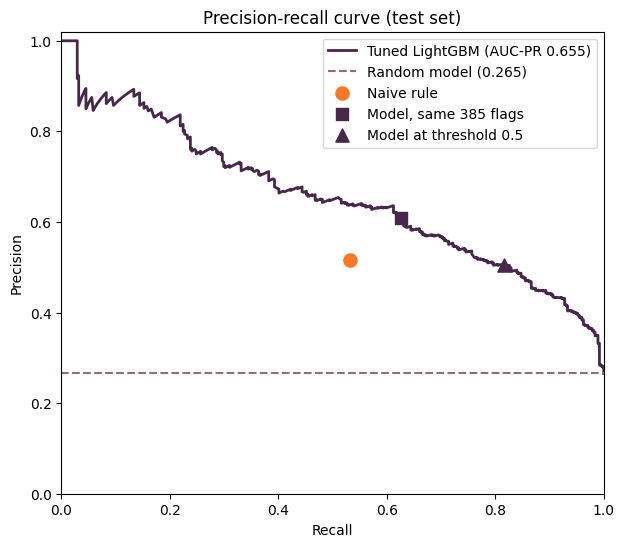

In [23]:
prec, rec, _ = precision_recall_curve(y, proba)
ap = average_precision_score(y, proba)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(rec, prec, color=PURPLE, lw=2, label=f"Tuned LightGBM (AUC-PR {ap:.3f})")
ax.axhline(churn_rate, color=MAUVE, ls="--", label=f"Random model ({churn_rate:.3f})")
ax.scatter(base_tp / n_churn, base_tp / k, color=ORANGE, s=90, zorder=5, label="Naive rule")
ax.scatter(topk_tp / n_churn, topk_tp / k, color=PURPLE, marker="s", s=80, zorder=5,
           label=f"Model, same {k} flags")
ax.scatter(thr_tp / n_churn, thr_tp / pred.sum(), color=PURPLE, marker="^", s=90, zorder=5,
           label=f"Model at threshold {threshold}")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-recall curve (test set)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(loc="upper right")
plt.savefig("../outputs/plots/pr_curve.png", dpi=150, bbox_inches="tight")
plt.show()

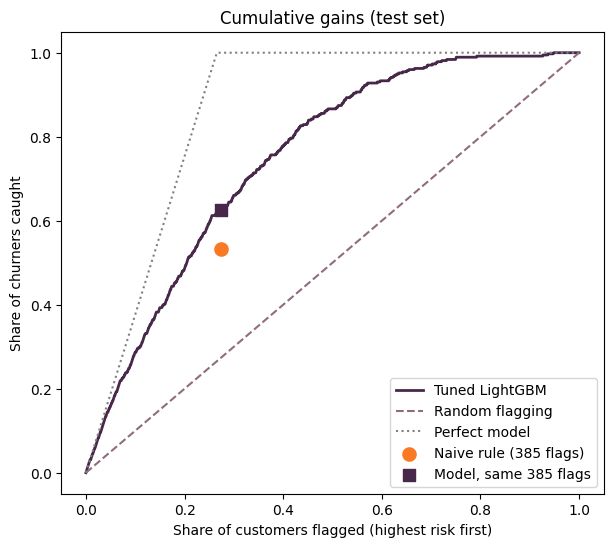

Top 10% riskiest -> catches 28.6% of churners
Top 20% riskiest -> catches 48.4% of churners
Top 30% riskiest -> catches 66.0% of churners
Top 40% riskiest -> catches 77.8% of churners


In [24]:
cum_caught = np.concatenate([[0], np.cumsum(y[order]) / n_churn])
pct_flagged = np.arange(0, n + 1) / n

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(pct_flagged, cum_caught, color=PURPLE, lw=2, label="Tuned LightGBM")
ax.plot([0, 1], [0, 1], color=MAUVE, ls="--", label="Random flagging")
ax.plot([0, churn_rate, 1], [0, 1, 1], color="gray", ls=":", label="Perfect model")
ax.scatter(k / n, base_tp / n_churn, color=ORANGE, s=90, zorder=5, label=f"Naive rule ({k} flags)")
ax.scatter(k / n, topk_tp / n_churn, color=PURPLE, marker="s", s=80, zorder=5,
           label=f"Model, same {k} flags")
ax.set_xlabel("Share of customers flagged (highest risk first)")
ax.set_ylabel("Share of churners caught")
ax.set_title("Cumulative gains (test set)")
ax.legend(loc="lower right")
plt.savefig("../outputs/plots/gains_curve.png", dpi=150, bbox_inches="tight")
plt.show()

for p in [0.1, 0.2, 0.3, 0.4]:
    m = int(p * n)
    print(f"Top {int(p*100)}% riskiest -> catches {y[order[:m]].sum() / n_churn:.1%} of churners")

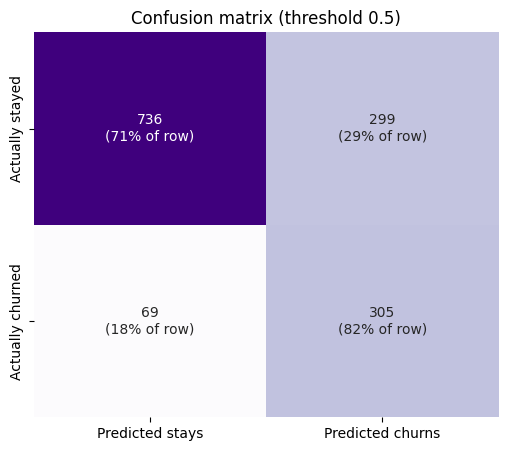

In [25]:
cm = confusion_matrix(y, pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True)
labels = np.array([[f"{cm[i, j]}\n({cm_pct[i, j]:.0%} of row)" for j in range(2)] for i in range(2)])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=labels, fmt="", cmap="Purples", cbar=False, ax=ax,
            xticklabels=["Predicted stays", "Predicted churns"],
            yticklabels=["Actually stayed", "Actually churned"])
ax.set_title(f"Confusion matrix (threshold {threshold})")
plt.savefig("../outputs/plots/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

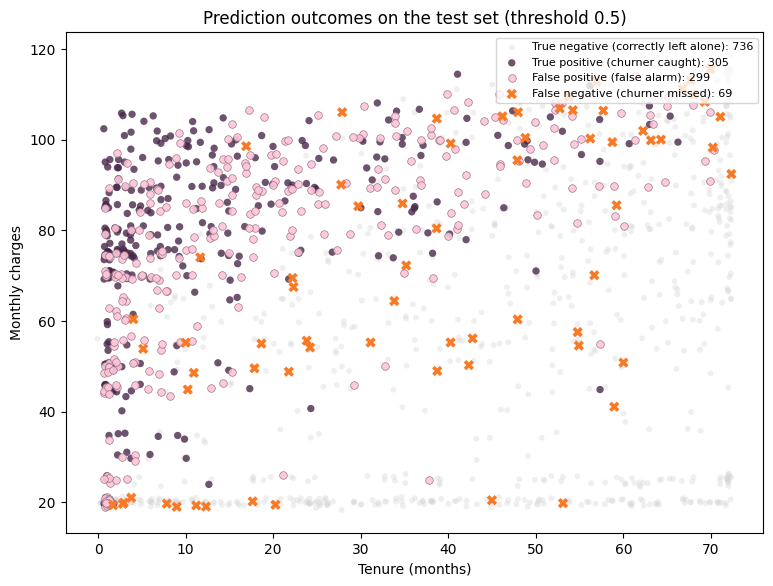

In [26]:
rng = np.random.default_rng(42)
tenure = X_test["tenure"].to_numpy() + rng.uniform(-0.35, 0.35, n)   # jitter for visibility only
charges = X_test["monthly_charges"].to_numpy()

groups = [  # drawn in this order, so the errors end up on top
    ("True negative (correctly left alone)", (y == 0) & (pred == 0), "lightgray", 0.35, 18, "o"),
    ("True positive (churner caught)",       (y == 1) & (pred == 1), PURPLE, 0.8, 28, "o"),
    ("False positive (false alarm)",         (y == 0) & (pred == 1), PINK, 0.9, 30, "o"),
    ("False negative (churner missed)",      (y == 1) & (pred == 0), ORANGE, 1.0, 55, "X"),
]

fig, ax = plt.subplots(figsize=(9, 6.5))
for label, mask, color, alpha, size, marker in groups:
    ax.scatter(tenure[mask], charges[mask], c=color, alpha=alpha, s=size, marker=marker,
               edgecolors=MAUVE if color == PINK else "none", linewidths=0.5,
               label=f"{label}: {mask.sum()}")
ax.set_xlabel("Tenure (months)"); ax.set_ylabel("Monthly charges")
ax.set_title(f"Prediction outcomes on the test set (threshold {threshold})")
ax.legend(loc="upper right", fontsize=8)
plt.savefig("../outputs/plots/outcome_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## Visual diagnostics: how the tuned LightGBM performs on the test set

Four plots were drawn on the 1,409 held-out customers (374 churners) at the placeholder cutoff of 0.5. The first two use only the *ranking* of customers by predicted risk, so they stay valid after calibration and threshold selection. The last two depend on the cutoff and will be redrawn once the final threshold is chosen. All are saved in `outputs/plots/`.

### 1. Precision-recall curve (AUC-PR 0.655)

**How it is built:** customers are sorted from highest to lowest predicted risk, and a cutoff slides down the list. At each position, recall (share of churners caught) and precision (share of flags that are real churners) are recorded. The dashed line at 0.265 is a random model, whose precision equals the churn rate at every recall. The naive rule is a single dot because it only gives yes/no, not a ranking.

**What it shows**
- The curve stays above the random line everywhere. At the naive rule's recall (0.53) the model is roughly 10 points more precise.
- The spike to precision 1.0 at the far left rests on a handful of customers (the first 10% of recall is only about 37 churners), so it is noise, not a feature.
- **The extra flags are weak bets.** Going from the equal-volume point (385 flags: recall 0.63, precision 0.61) to the 0.5 cutoff (604 flags: recall 0.82, precision 0.505), the extra 219 flags catch only 71 more churners. About 32% of those flags are real churners, barely above the 26.5% base rate. Whether such a flag deserves a discount depends on the discount cost versus the value of a retained customer, which is why the cutoff is chosen from costs and not left at 0.5.

### 2. Cumulative gains curve

**How the reference lines are built**
- *Random:* flagging x% of customers at random catches x% of churners, a straight diagonal.
- *Perfect:* a model that ranked every churner above every non-churner catches only churners until they run out. Churners are 26.5% of customers, so it catches x / 0.265 of them while flagging the top x, hits 100% at x = 26.5%, then stays flat. It is a theoretical ceiling, drawn from the churn rate alone, not an achievable model.

**What it shows**
- Flagging the riskiest 10% of customers catches 28.6% of churners (about 2.9x random), the top 20% catch 48.4%, the top 30% catch 66.0%, and the top 40% catch 77.8%.
- Lift is strongest at the top and fades. After the top 40%, the remaining 22% of churners are spread across the other 60% of customers, so the model cannot find them.
- At the same 385 flags as the naive rule, the model catches 62.6% of churners against 53.2%.

### 3. Confusion matrix heatmap

Read by row: 82% of churners are caught (305 of 374) and 71% of loyal customers are correctly left alone (736 of 1,035). The other 29% of loyal customers (299) are false alarms, each a wasted retention offer. This plot is redrawn at the final threshold.

### 4. Outcome scatter (tenure × monthly charges)

**Why these two features:** a scatter shows only two features and the model uses 30. Tenure and monthly charges were chosen because they had the clearest numeric churn signal in EDA (churners have lower tenure and higher bills), are weakly correlated (0.25), and `total_charges` was left out because it is mostly tenure × monthly charges (0.83 correlation with tenure). This is a choice for the picture only. The model itself uses all 30 features, including contract, payment method and internet service, which this plot cannot show.

**No decision boundary is drawn:** the boundary lives in 30 dimensions, so any line in this 2D view would be an approximation that misleads.

**What it shows (read approximately from the plot)**
- True positives and false positives both pile up in the first ~12 months of tenure with mid-to-high bills, and the two colors are mixed together there. On these two features alone, a new customer who will churn and one who will stay look the same. The model separates them using the other features.
- Missed churners (69) sit mostly outside that zone: spread across long tenures, and along the bottom band at about 20 monthly charges (likely phone-only plans, where EDA showed churn is low). These are churners whose profile looks safe, the model's blind spot. With only 69 points, this is a pattern worth checking, not proof.
- Long-tenure and cheap-plan customers are mostly correctly left alone (gray).

### Takeaways
- Ranking quality is good: the model beats both random flagging and the naive rule.
- The model is not precise at the margin. Beyond roughly the top 385 flags, only about a third of extra flags are real churners.
- There is a hard core of churners who look low-risk, which neither plot can fix.
- Next: calibrate the probabilities, choose the cutoff from costs, then redraw the heatmap and scatter at that cutoff.

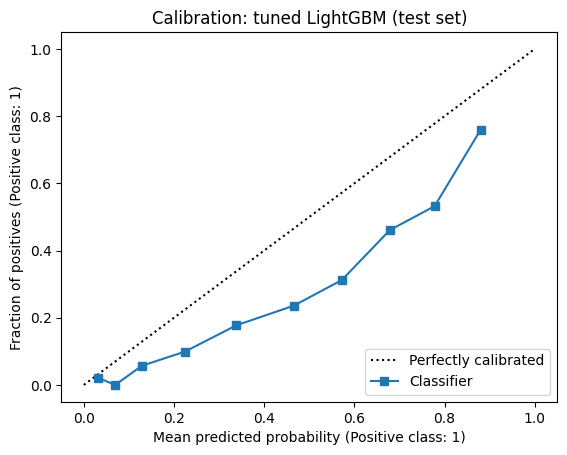

Mean predicted probability: 0.417
Actual churn rate         : 0.265


In [27]:
from sklearn.calibration import CalibrationDisplay
import matplotlib.pyplot as plt

CalibrationDisplay.from_predictions(y_test, proba, n_bins=10, strategy="quantile")
plt.title("Calibration: tuned LightGBM (test set)")
plt.show()

print("Mean predicted probability:", round(proba.mean(), 3))
print("Actual churn rate         :", round(float(np.mean(y_test)), 3))

## Calibration diagnostic: reading the curve

### What the plot asks
When the model says a customer has an X% chance of churning, how often does that customer actually churn? A well-calibrated model answers "about X%" at every score. ("Positive class" in the axis labels means churn.)

### How it is built
- **x-axis (mean predicted probability):** what the model says.
- **y-axis (fraction of positives):** what actually happened.
- **Dotted diagonal:** perfect calibration, where say equals actual.
- **Blue line:** the model's real record, one point per group.

The 1,409 test customers are sorted by predicted probability and split into 10 equal groups of about 141 customers (`n_bins=10, strategy="quantile"`). Each point is one group: its x is the group's average predicted probability and its y is the share of that group who actually churned. Equal-sized groups explain why the points bunch up on the left, since the lowest three groups (average scores 0.03 to 0.13) are mostly long-tenure loyal customers.

### Readings (approximate, read off the plot by eye)

| Model says (group average) | Actually churned | Gap |
|---|---|---|
| 0.03 | 0.02 | 0.01 |
| 0.07 | 0.00 | 0.07 |
| 0.13 | 0.06 | 0.07 |
| 0.22 | 0.10 | 0.12 |
| 0.34 | 0.18 | 0.16 |
| 0.47 | 0.24 | 0.23 |
| 0.57 | 0.31 | 0.26 |
| 0.68 | 0.46 | 0.22 |
| 0.78 | 0.53 | 0.25 |
| 0.88 | 0.76 | 0.12 |

### Findings
1. **The model overstates churn risk at every score.** All ten points sit below the diagonal. A customer shown at 0.57 churns about 31% of the time. The ten x-values average about 0.417 and the ten y-values about 0.265, matching the printed mean predicted probability (0.417) and actual churn rate (0.265).
2. **The ranking is sound.** The line rises steadily, so higher scores do mean higher real churn. This is why AUC-PR and the gains curve are unaffected. Only the scale is wrong, which makes the problem fixable by rescaling.
3. **The gap is largest in the middle** (about 0.22 to 0.26 for scores of 0.47 to 0.78) and smaller at the extremes.
4. **How much to trust the wiggles:** each point rests on about 141 customers, so its sampling error is roughly 4 points (one standard error). Small bumps, such as the dip at 0.07 or the jump at 0.88, are noise. A gap of 0.2 or more is about five times larger, so it is a real effect.

### Likely cause: class weighting
The model was trained with `scale_pos_weight` (about 2.77), which makes a missed churner count about 2.77 times more. That multiplies every customer's odds of churn by roughly 2.77. Dividing the odds back by 2.77 should therefore recover the real rate, and on the plot readings it does:

| Model says | Odds divided by 2.77 | Actual |
|---|---|---|
| 0.34 | 0.16 | 0.18 |
| 0.47 | 0.24 | 0.24 |
| 0.57 | 0.32 | 0.31 |
| 0.68 | 0.43 | 0.46 |
| 0.78 | 0.56 | 0.53 |
| 0.88 | 0.73 | 0.76 |

The match is within about 3 points everywhere, inside the sampling noise. This is consistent with class weighting as the cause, but it is not proof, since the readings are eyeballed. The direct test is to compare against a model trained without the weight.

### Why this matters here
A customer the app would show as "70% chance of churn" really has about a 45% chance. The cost-based cutoff multiplies probability by revenue and discount cost, so inflated probabilities would flag the wrong customers and overstate the savings. A smooth, steady distortion like this can be corrected by a simple monotonic mapping (calibration), which leaves the ranking unchanged.

### Next
Fit sigmoid and isotonic calibrators on training data only, then re-draw this curve on the test set. After calibration the blue line should sit close to the diagonal and the mean predicted probability should move close to 0.265.

uncalibrated  | Brier: 0.1659 | AUC-PR: 0.6550 | mean pred: 0.417
sigmoid       | Brier: 0.1369 | AUC-PR: 0.6550 | mean pred: 0.269
isotonic      | Brier: 0.1369 | AUC-PR: 0.6398 | mean pred: 0.268


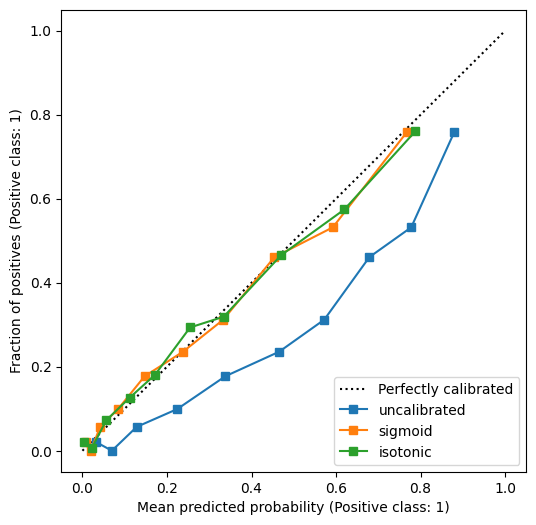

In [28]:
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import brier_score_loss

base = LGBMClassifier(scale_pos_weight=scale_pos_weight, random_state=42,
                      verbose=-1, n_jobs=1, **final_params)

cal_sigmoid = CalibratedClassifierCV(base, method="sigmoid", cv=cv_5, ensemble=False)
cal_sigmoid.fit(X_train, y_train)

cal_isotonic = CalibratedClassifierCV(base, method="isotonic", cv=cv_5, ensemble=False)
cal_isotonic.fit(X_train, y_train)

results = {
    "uncalibrated": proba,
    "sigmoid": cal_sigmoid.predict_proba(X_test)[:, 1],
    "isotonic": cal_isotonic.predict_proba(X_test)[:, 1],
}

for name, p in results.items():
    print(f"{name:13s} | Brier: {brier_score_loss(y_test, p):.4f} | "
          f"AUC-PR: {average_precision_score(y_test, p):.4f} | mean pred: {p.mean():.3f}")

fig, ax = plt.subplots(figsize=(6, 6))
for name, p in results.items():
    CalibrationDisplay.from_predictions(y_test, p, n_bins=10, strategy="quantile",
                                        name=name, ax=ax)
plt.show()

## Calibration results: sigmoid vs. isotonic

### The terms
- **Calibration:** rescaling the model's scores so they match real outcomes. A calibrated 0.3 means about 30% of those customers churn. It reshapes scores without reordering customers.
- **Sigmoid (Platt scaling):** fits a smooth S-shaped curve with two learned numbers that maps the raw score to the observed churn rate. It has few parameters, so it is stable on a few thousand rows, and it is a strictly increasing curve, so no two customers swap places.
- **Isotonic:** learns a flexible step-shaped mapping with no assumed shape. It can fix irregular distortions, but it needs more data to stay stable, and because it maps scores to steps, customers with different raw scores can end up with the identical probability (ties).
- **Brier score:** the average squared gap between the predicted probability and what happened (1 if the customer churned, 0 if not). Lower is better, 0 is perfect. Predicting the churn rate (0.265) for everyone scores about 0.195, so that is the reference to beat.

### How the calibrators were fit
Both were fit on the training set only, using out-of-fold predictions from 5-fold cross-validation (`CalibratedClassifierCV` with `ensemble=False`). The underlying LightGBM model is the same one fit on all training data. The test set was used only to check the result.

### Results (test set)

| | Brier | AUC-PR | Mean predicted probability |
|---|---|---|---|
| Uncalibrated | 0.1659 | 0.6550 | 0.417 |
| Sigmoid | 0.1369 | 0.6550 | 0.269 |
| Isotonic | 0.1369 | 0.6398 | 0.268 |

The actual churn rate is 0.265.

### What the numbers show
- **The inflation is fixed.** The mean predicted probability fell from 0.417 to about 0.27 with both calibrators, matching the real 0.265.
- **Brier improved by about 17%** (0.1659 to 0.1369). Relative to the 0.195 reference, the model went from about 15% better than predicting the churn rate for everyone to about 30% better. The model and the ranking are unchanged, and only the probabilities improved.
- **Sigmoid kept the ranking exactly.** AUC-PR stayed at 0.6550, as expected for a smooth, strictly increasing mapping.
- **Isotonic lost ranking information.** AUC-PR fell to 0.6398 with no Brier gain over sigmoid, consistent with its step mapping creating ties between customers who differ in raw score.

### Reading the calibration plot
- **Blue (uncalibrated)** is the earlier curve, below the diagonal at every point.
- **Orange (sigmoid) and green (isotonic)** both sit close to the diagonal, for example customers scored about 0.46 now churn about 46% of the time (before: about 24%). Remaining wiggles are within the roughly 4-point noise of a bin of about 141 customers.
- **The calibrated curves end near 0.78 on the x-axis.** The riskiest 10% of customers, previously shown at about 0.88, now show about 0.77, which matches how often they churn (about 76%). The app will rarely show a probability above 0.8, and that is honest, because no group of customers in this data churns that often.
- The two curves overlap because the original distortion was smooth, so the extra flexibility of isotonic had nothing to fit.

### Decision
**Sigmoid is the calibrator.** It matches isotonic on Brier, keeps the ranking intact, and is smoother and simpler. This was the rule set before the comparison: keep sigmoid unless isotonic is clearly better. The fitted `cal_sigmoid` is carried forward and saved with the model.

### Consequences for the next steps
- At a 0.5 cutoff, far fewer customers are now flagged and recall will drop. 0.5 now means a real 50% chance of churn, so this is expected.
- The cost-based cutoff multiplies probability by revenue and discount cost, which is now valid because the probabilities are honest.
- The AUC-PR, precision-recall curve and gains curve drawn earlier remain valid, since they depend only on the ranking. The confusion matrix and outcome scatter are redrawn at the final cutoff.

# Business assumptions for the cutoff

The retention offer goes to every customer the model flags, since there is no way to know in advance who will accept it.

### Assumptions

| Symbol | Meaning | Value | Source |
|---|---|---|---|
| r | Offer success rate: share of flagged churners who accept and stay | 0.5 | Q5 wording in the project plan. An assumption, not measured |
| d | Discount, as a share of the monthly bill | 0.2 | Chosen here (the first Q5 attempt hid a 50% discount inside the code) |
| M | Months a retained customer stays | 12 | Chosen |
| B | Customer's monthly bill | per customer | `monthly_charges` |

r is not the usual business metric "customer retention rate" (the share of all customers who stay), so it is called the offer success rate.

**Why r cannot be measured here:** the data is a snapshot in which nobody received an offer. A real A/B test would randomly split flagged customers into an offer group and a no-offer group and compare how many stay after 12 months, and the measured r would replace this assumption. Since r is a guess, results are shown for several values of r, along with the break-even r.

### Money effect of flagging one customer (versus making no offer)

| Outcome | Chance | Pays per month without offer | Pays per month with offer | Effect over M months |
|---|---|---|---|---|
| Churner accepts | p × r | 0 (leaves) | B × (1 − d) | + M × B × (1 − d) |
| Churner refuses | p × (1 − r) | 0 | 0 | 0 |
| Loyal customer (false alarm) | 1 − p | B | B × (1 − d) | − M × B × d |

A churner's discounted bill is all new revenue, because without the offer they would pay nothing. A loyal customer would have paid the full bill anyway, so the discount only removes d × B.

Expected gain from flagging one customer: M × B × [ p × r × (1 − d) − (1 − p) × d ], where p is the calibrated churn probability.

### Cutoff rule
Flag a customer when this gain is above zero. M × B appears in both terms and cancels, which leaves p > d / (d + r × (1 − d)). With r = 0.5 and d = 0.2 the cutoff is 0.2 / 0.6 = 0.33.

| r | d | Cutoff |
|---|---|---|
| 0.3 | 0.2 | 0.45 |
| 0.5 | 0.2 | 0.33 |
| 0.7 | 0.2 | 0.26 |
| 0.5 | 0.1 | 0.18 |
| 0.5 | 0.3 | 0.46 |

### How it is applied
Model score, then sigmoid calibration to get p, then flag the customer if p is at or above the cutoff, then add up the per-customer gains over all flagged customers for the campaign total. Two totals are computed: an **expected** total that uses p, and an **actual-label** total that uses each test customer's real churn outcome (churners still use the assumed r, because acceptance is unknown). If calibration is sound, the two should be close.

The cutoff comes from the rule above, which uses no test outcomes. The sweep over cutoffs is a check on that choice, not a search for the best-looking number on the test set.

### Simplifications
The same 12 months is used for gains and costs, contact costs are ignored, every false alarm is assumed to take the discount, and all totals are for the 1,409 test customers only (about 20% of the base).

In [29]:
import numpy as np
import pandas as pd

r, d, M = 0.5, 0.2, 12                              # offer success rate, discount, months retained

p_cal = cal_sigmoid.predict_proba(X_test)[:, 1]     # calibrated churn probability
B = X_test["monthly_charges"].to_numpy()            # each customer's monthly bill
y = np.asarray(y_test).astype(int)                  # actual churn (0/1)
n_churn = y.sum()

rows = []
for t in np.arange(0, 1.001, 0.01):
    flag = p_cal >= t
    hit = flag & (y == 1)            # flagged churners
    false_alarm = flag & (y == 0)    # flagged loyal customers

    actual = M * (r * (1 - d) * B[hit].sum() - d * B[false_alarm].sum())
    expected = M * (B[flag] * (p_cal[flag] * r * (1 - d) - (1 - p_cal[flag]) * d)).sum()

    rows.append({
        "cutoff": round(t, 2),
        "flagged": int(flag.sum()),
        "recall": hit.sum() / n_churn,
        "precision": hit.sum() / flag.sum() if flag.sum() > 0 else np.nan,
        "actual_saving": actual,
        "expected_saving": expected,
    })

sweep = pd.DataFrame(rows)
cutoff_rule = d / (d + r * (1 - d))
print("Cutoff from the rule:", round(cutoff_rule, 3))
sweep.iloc[::10]      # every 0.1, to keep the output short

Cutoff from the rule: 0.333


,cutoff,flagged,recall,precision,actual_saving,expected_saving
0,0.0,1409,1.000000,0.265436,-17131.80,-15690.523361
10,0.1,873,0.941176,0.403207,40805.64,44313.427258
20,0.2,681,0.855615,0.469897,54904.56,60918.192881
30,0.3,548,0.764706,0.521898,60441.24,66588.224326
40,0.4,403,0.636364,0.590571,61693.20,65544.860626
50,0.5,310,0.529412,0.638710,56406.72,59369.883641
60,0.6,199,0.377005,0.708543,43876.56,45839.676751
70,0.7,115,0.237968,0.773913,30013.20,31057.788430
80,0.8,46,0.106952,0.869565,14896.32,14389.355787
90,0.9,4,0.010695,1.000000,1727.28,1516.435831


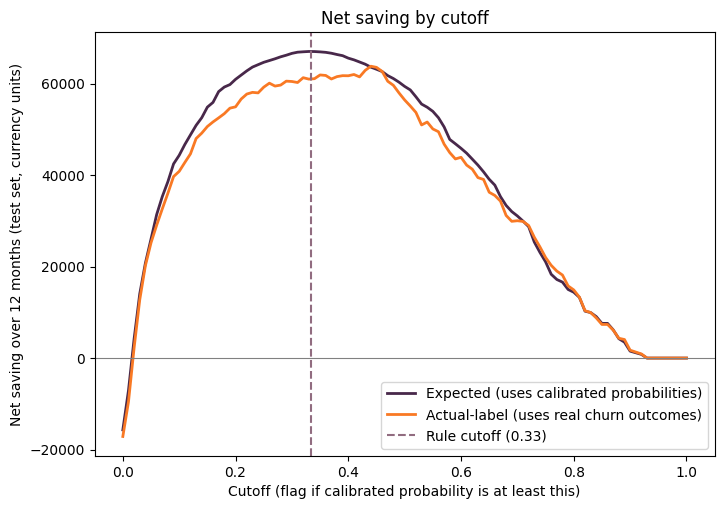

cutoff 0.00 | flagged 1409 | recall 1.00 | precision 0.27 | actual saving -17,132 | expected saving -15,691
cutoff 0.33 | flagged 501 | recall 0.73 | precision 0.54 | actual saving 60,962 | expected saving 67,003
cutoff 0.50 | flagged 310 | recall 0.53 | precision 0.64 | actual saving 56,407 | expected saving 59,370
Highest actual-label saving at cutoff 0.44 -> 63,780


In [30]:
import matplotlib.pyplot as plt

PURPLE, ORANGE, MAUVE = "#48284a", "#f97924", "#916c80"

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(sweep.cutoff, sweep.expected_saving, color=PURPLE, lw=2,
        label="Expected (uses calibrated probabilities)")
ax.plot(sweep.cutoff, sweep.actual_saving, color=ORANGE, lw=2,
        label="Actual-label (uses real churn outcomes)")
ax.axvline(cutoff_rule, color=MAUVE, ls="--", label=f"Rule cutoff ({cutoff_rule:.2f})")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("Cutoff (flag if calibrated probability is at least this)")
ax.set_ylabel("Net saving over 12 months (test set, currency units)")
ax.set_title("Net saving by cutoff")
ax.legend()
plt.savefig("../outputs/plots/cutoff_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

for t in [0.0, cutoff_rule, 0.5]:
    row = sweep.iloc[(sweep.cutoff - t).abs().idxmin()]
    print(f"cutoff {row.cutoff:.2f} | flagged {int(row.flagged)} | recall {row.recall:.2f} | "
          f"precision {row.precision:.2f} | actual saving {row.actual_saving:,.0f} | "
          f"expected saving {row.expected_saving:,.0f}")

best = sweep.loc[sweep.actual_saving.idxmax()]
print("Highest actual-label saving at cutoff", best.cutoff, "->", f"{best.actual_saving:,.0f}")

## Cost sweep: net saving by cutoff

### What was computed
For every cutoff from 0 to 1 (step 0.01), customers whose calibrated churn probability is at or above the cutoff are flagged for the offer, and the 12-month net saving over the 1,409 test customers is added up under the assumptions above (r = 0.5, d = 0.2, M = 12). Two totals are shown:
- **Expected saving** uses each customer's calibrated probability.
- **Actual-label saving** uses each customer's real churn outcome. Flagged churners still use the assumed 50% acceptance, because acceptance is not in the data.

### Results (test set, currency units)

| Cutoff | Flagged | Recall | Precision | Actual-label saving | Expected saving |
|---|---|---|---|---|---|
| 0.0 | 1,409 | 1.00 | 0.27 | -17,132 | -15,691 |
| 0.1 | 873 | 0.94 | 0.40 | 40,806 | 44,313 |
| 0.2 | 681 | 0.86 | 0.47 | 54,905 | 60,918 |
| 0.3 | 548 | 0.76 | 0.52 | 60,441 | 66,588 |
| **0.33 (rule)** | **501** | **0.73** | **0.54** | **60,962** | **67,003** |
| 0.4 | 403 | 0.64 | 0.59 | 61,693 | 65,545 |
| 0.5 | 310 | 0.53 | 0.64 | 56,407 | 59,370 |
| 0.6 | 199 | 0.38 | 0.71 | 43,877 | 45,840 |
| 0.7 | 115 | 0.24 | 0.77 | 30,013 | 31,058 |
| 0.8 | 46 | 0.11 | 0.87 | 14,896 | 14,389 |
| 0.9 | 4 | 0.01 | 1.00 | 1,727 | 1,516 |

### Reading the plot
1. **Untargeted offers lose money.** Flagging all 1,409 customers costs 17,132. The overall churn rate (0.265) is below the break-even probability (0.33), so a blanket campaign gives away more in discounts to loyal customers than it saves. Targeting is what makes the campaign pay.
2. **The curve rises steeply, plateaus, then falls.** Too loose a cutoff wastes discounts on loyal customers. Too strict a cutoff leaves retainable churners alone. Between about 0.3 and 0.45 the actual-label saving stays within about 5% of its maximum.
3. **The expected curve peaks at 0.33 by construction**, since the rule says a customer adds value exactly when their probability is above 0.33. The peak itself is therefore not evidence. The check is that the actual-label curve tracks the expected one. The actual-label total is about 6,000 (9%) below the expected total at 0.33, which is about the size of the sampling noise from 501 flagged customers (roughly 6,000, a rough estimate), so it does not indicate a calibration problem.
4. **The actual-label peak (0.44, saving 63,780) is not used.** It is only 2,818 (4.6%) above the 0.33 result, smaller than the noise, and picking the best-looking point on a single test set would overfit it. The cutoff stays at the rule's 0.33, which was derived before looking at any test outcomes.

### Decision
**Cutoff = 0.33**, flagging 501 of 1,409 customers (36%). At this cutoff the model catches 73% of churners at 54% precision, with a 12-month net saving of 60,962 on the test set (the more conservative actual-label figure), about 43,300 per 1,000 customers.

### Relation to the earlier 0.5 placeholder
The old 0.5 was applied to inflated scores and flagged 604 customers. Calibration does not reorder customers, so those are the same top 604, which corresponds to a calibrated cutoff of about 0.25. The cost-based 0.33 is slightly stricter and flags 501.

### Caveats
- All savings scale with the assumed offer success rate (r = 0.5), which is not measured. A sensitivity table and the break-even r follow.
- Totals cover the 1,409 test customers only (about 20% of the base), not the whole company.
- Contact costs are ignored, and every false alarm is assumed to take the discount.
- This is the saving relative to making no offers. It has not yet been compared with other targeting strategies.

## Strategy comparison and sensitivity

The 12-month saving at the chosen cutoff means little on its own, so it is compared with simpler ways of spending the same retention budget, all under the same assumptions (r = 0.5, d = 0.2, M = 12) and scored on the same 1,409 test customers using real churn outcomes:

- **No offers:** the zero reference.
- **Offer to everyone:** a blanket campaign.
- **Random flagging:** the expected result of flagging the same number of customers at random.
- **Naive rule:** month-to-month and tenure under 12 months (385 flags).
- **Model, same flags as the naive rule:** the model's top 385 customers, a like-for-like comparison.
- **Model at the cost-based cutoff (0.33).**
- **Perfect knowledge:** flag exactly the real churners. An unreachable ceiling that shows how much room is left.

A bootstrap (2,000 resamples of the test customers) gives a 95% interval for the model's saving minus the naive rule's saving. It covers sampling noise in the test set only, not uncertainty in r.

Since r = 0.5 is an assumption, a second table repeats the analysis for r from 0.1 to 0.7 and reports the **break-even r**: the lowest offer success rate at which a policy still makes money.

,strategy,net_saving,per_1000_customers
0,No offers,0,0.0
1,Offer to everyone,-17132,-12159.0
2,"Random, same 496 flags (expected)",-6031,-4280.0
3,Naive rule (385 flags),43079,30574.0
4,"Model, same 385 flags",62382,44274.0
5,Model at cutoff 0.33 (496 flags),60674,43062.0
6,Perfect knowledge (ceiling),136633,96972.0


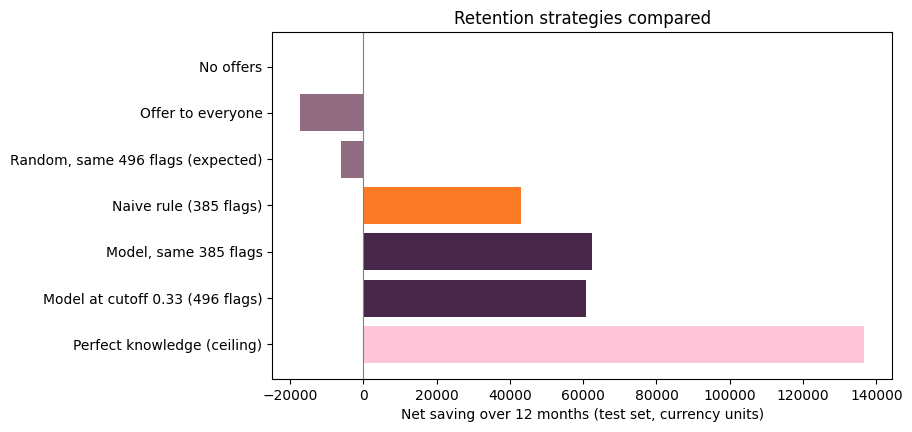

Model at 0.33 minus naive rule: mean 17,661 | 95% interval 8,676 to 27,360
Model (same 385 flags) minus naive rule: mean 19,367 | 95% interval 10,746 to 27,903


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PURPLE, ORANGE, MAUVE, PINK = "#48284a", "#f97924", "#916c80", "#ffc6d9"

def net_saving(flag, y_, B_, r=r, d=d, M=M):
    hit = flag & (y_ == 1)            # flagged churners
    false_alarm = flag & (y_ == 0)    # flagged loyal customers
    return M * (r * (1 - d) * B_[hit].sum() - d * B_[false_alarm].sum())

n = len(y)
flag_all = np.ones(n, dtype=bool)
flag_naive = np.asarray(base_pred).astype(bool)
k = int(flag_naive.sum())                                   # naive rule's flag count
order = np.argsort(-p_cal)
flag_topk = np.zeros(n, dtype=bool); flag_topk[order[:k]] = True
flag_model = p_cal >= cutoff_rule
flag_perfect = (y == 1)

s_all = net_saving(flag_all, y, B)
results = {
    "No offers": 0.0,
    "Offer to everyone": s_all,
    f"Random, same {flag_model.sum()} flags (expected)": flag_model.sum() / n * s_all,
    f"Naive rule ({k} flags)": net_saving(flag_naive, y, B),
    f"Model, same {k} flags": net_saving(flag_topk, y, B),
    f"Model at cutoff {cutoff_rule:.2f} ({flag_model.sum()} flags)": net_saving(flag_model, y, B),
    "Perfect knowledge (ceiling)": net_saving(flag_perfect, y, B),
}

comp = pd.DataFrame({"strategy": list(results.keys()),
                     "net_saving": [round(v) for v in results.values()]})
comp["per_1000_customers"] = (comp.net_saving / n * 1000).round()
display(comp)

# bar chart
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = [MAUVE, MAUVE, MAUVE, ORANGE, PURPLE, PURPLE, PINK]
ax.barh(comp.strategy[::-1], comp.net_saving[::-1], color=colors[::-1])
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("Net saving over 12 months (test set, currency units)")
ax.set_title("Retention strategies compared")
plt.savefig("../outputs/plots/strategy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# bootstrap interval for the gain over the naive rule (paired: same resample for both)
rng = np.random.default_rng(42)
gain_cut, gain_topk = [], []
for _ in range(2000):
    idx = rng.integers(0, n, n)
    yb, Bb = y[idx], B[idx]
    s_naive = net_saving(flag_naive[idx], yb, Bb)
    gain_cut.append(net_saving(flag_model[idx], yb, Bb) - s_naive)
    gain_topk.append(net_saving(flag_topk[idx], yb, Bb) - s_naive)

for name, arr in [(f"Model at {cutoff_rule:.2f} minus naive rule", gain_cut),
                  (f"Model (same {k} flags) minus naive rule", gain_topk)]:
    lo, hi = np.percentile(arr, [2.5, 97.5])
    print(f"{name}: mean {np.mean(arr):,.0f} | 95% interval {lo:,.0f} to {hi:,.0f}")

In [32]:
rows = []
for r_ in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    cut_r = d / (d + r_ * (1 - d))            # the rule's cutoff for this r
    flag_r = p_cal >= cut_r
    rows.append({
        "r": r_,
        "rule_cutoff": round(cut_r, 2),
        "flagged_at_rule_cutoff": int(flag_r.sum()),
        "saving_at_rule_cutoff": round(net_saving(flag_r, y, B, r=r_)),
        "saving_if_cutoff_stays_0.33": round(net_saving(flag_model, y, B, r=r_)),
        "naive_rule": round(net_saving(flag_naive, y, B, r=r_)),
        "offer_everyone": round(net_saving(flag_all, y, B, r=r_)),
    })
sens = pd.DataFrame(rows)
display(sens)

def breakeven_r(flag):
    hit = flag & (y == 1); fa = flag & (y == 0)
    return d * B[fa].sum() / ((1 - d) * B[hit].sum())   # saving = 0 solved for r

print("Break-even r, model at 0.33  :", round(breakeven_r(flag_model), 3))
print("Break-even r, naive rule     :", round(breakeven_r(flag_naive), 3))
print("Break-even r, offer everyone :", round(breakeven_r(flag_all), 3))

,r,rule_cutoff,flagged_at_rule_cutoff,saving_at_rule_cutoff,saving_if_cutoff_stays_0.33,naive_rule,offer_everyone
0,0.1,0.71,106,2553,-21134,-9288,-126439
1,0.2,0.56,251,10439,-682,3804,-99112
2,0.3,0.45,354,28420,19770,16896,-71785
3,0.4,0.38,428,42581,40222,29987,-44458
4,0.5,0.33,496,60674,60674,43079,-17132
5,0.6,0.29,560,82395,81126,56171,10195
6,0.7,0.26,604,104828,101578,69263,37522


Break-even r, model at 0.33  : 0.203
Break-even r, naive rule     : 0.171
Break-even r, offer everyone : 0.563


## Strategy comparison and sensitivity: results

All strategies use the same assumptions (r = 0.5, d = 0.2, M = 12) and are scored with real churn outcomes on the 1,409 test customers. Savings are net 12-month revenue relative to making no offers, in currency units.

### Strategy comparison

| Strategy | Net saving | Per 1,000 customers |
|---|---|---|
| No offers | 0 | 0 |
| Offer to everyone | -17,132 | -12,159 |
| Random flagging, same 496 flags (expected) | -6,031 | -4,280 |
| Naive rule (month-to-month and tenure under 12 months, 385 flags) | 43,079 | 30,574 |
| Model, same 385 flags | 62,382 | 44,274 |
| **Model at the cost-based cutoff 0.33 (496 flags)** | **60,674** | **43,062** |
| Perfect knowledge (ceiling) | 136,633 | 96,972 |

**Gain over the naive rule (paired bootstrap, 2,000 resamples of the test customers):**
- Model at 0.33 minus naive rule: mean 17,661, 95% interval 8,676 to 27,360.
- Model with the same 385 flags minus naive rule: mean 19,367, 95% interval 10,746 to 27,903.

Both intervals sit entirely above zero, so the gain is not an artifact of this particular sample. They cover test-sample noise only, not uncertainty in r, d and M.

### What the comparison shows
1. **Untargeted offers lose money.** The overall churn rate (0.265) is below the break-even probability (0.33), so flagging at random (-6,031) or flagging everyone (-17,132) gives away more in discounts to loyal customers than it saves. Only an informative ranking makes the campaign pay.
2. **The naive rule is already profitable** (43,079), because new month-to-month customers churn at a rate above the break-even.
3. **The model earns about 41% more than the naive rule** (60,674 against 43,079, a gain of about 17,600 on 1,409 customers, or about 12,500 per 1,000). Using the same 385 flags, the gain is about 19,300, so the advantage comes from picking better customers, not from flagging more.
4. **Share of the ceiling captured:** the model captures about 44% of the saving a perfect-knowledge policy would achieve, the naive rule about 32%. The perfect-knowledge figure assumes every churner can be identified in advance, so it is a ceiling and not a target.
5. **The 385-flag model (62,382) edges out the 0.33 cutoff (60,674).** The difference is under 3% and sits on the flat plateau of the cutoff sweep (0.3 to 0.45), so it is within noise. The cutoff stays at the cost-based 0.33, which was derived before looking at test outcomes.

### Sensitivity to the offer success rate r
r = 0.5 is an assumption, not a measurement. The table shows each policy at other values of r. "Cutoff adapted" re-derives the cutoff for each r (d / (d + r(1 - d))). "Cutoff kept at 0.33" shows what happens if r turns out different and the cutoff is not changed.

| r | Rule cutoff | Flagged | Saving, cutoff adapted | Saving, cutoff kept at 0.33 | Naive rule |
|---|---|---|---|---|---|
| 0.1 | 0.71 | 106 | 2,553 | -21,134 | ~-9,300 |
| 0.2 | 0.56 | 251 | 10,439 | -682 | ~3,800 |
| 0.3 | 0.45 | 354 | 28,420 | 19,770 | ~16,900 |
| 0.4 | 0.38 | 428 | 42,581 | 40,222 | ~30,000 |
| 0.5 | 0.33 | 496 | 60,674 | 60,674 | 43,079 |
| 0.6 | 0.29 | 560 | 82,395 | 81,126 | ~56,200 |
| 0.7 | 0.26 | 604 | 104,828 | 101,578 | ~69,300 |

(Naive-rule values marked ~ are rounded from the printed output.)

**Break-even r** (the lowest offer success rate at which a policy, with its flagged set held fixed, still makes money):
- Model at 0.33: **0.203**
- Naive rule: 0.171
- Offer to everyone: 0.563

### What the sensitivity shows
1. **The campaign has a wide margin of safety.** The model at 0.33 stays profitable for any r above about 0.20, which is 40% of the assumed 0.5. A blanket campaign needs r above 0.56, which is why it loses money at 0.5.
2. **The model beats the naive rule at every r tested.** At r = 0.1 the naive rule loses about 9,300 while the model, with its cutoff raised to 0.71 (106 flags), still gains 2,553.
3. **Adapting the cutoff matters when offers work worse than assumed.** At r = 0.2, keeping 0.33 loses 682 while the adapted cutoff (0.56) gains 10,439. At r = 0.3, adapting adds about 8,650 (19,770 to 28,420).
4. **The risk is asymmetric.** If offers work better than assumed, keeping 0.33 gives up little (1.5% at r = 0.6, 3.1% at r = 0.7). A cutoff that is too loose when offers work worse costs far more. This is the reason for letting the app recompute the cutoff from the r and discount inputs.

### Decision
**Final cutoff = 0.333** (d / (d + r(1 - d)) with r = 0.5 and d = 0.2), flagging 496 of 1,409 test customers (35%) with a 12-month net saving of 60,674 (about 43,100 per 1,000 customers). The exact rule cutoff (0.3333) flags 496 customers; the earlier sweep's 0.01 grid rounds it to 0.33 and 501.

### Caveats
- r, d and M are assumptions. The data contains no offers, so r cannot be measured here. In practice it would come from an A/B test of flagged customers, and the measured value would replace the assumption.
- Totals cover the 1,409 test customers (about 20% of the base), not the whole company, and are in currency units because the data has no currency.
- Contact costs are ignored, every false alarm is assumed to take the discount, and gains and costs both use 12 months.
- The bootstrap interval reflects sampling noise in the test set only.

## Final-cutoff diagnostics

The confusion matrix and outcome scatter are redrawn at the final cutoff (0.333, from the cost rule) using sigmoid-calibrated probabilities. The earlier versions used raw scores at the 0.5 placeholder. A segment table (recall and precision by contract type and by tenure band) shows where the model does and does not catch churners.

Cutoff 0.3333 | flagged 496 of 1409 | recall 0.725 | precision 0.546


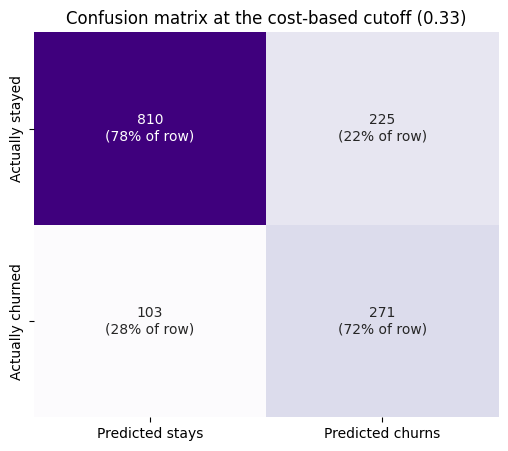

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, recall_score, precision_score

PURPLE, ORANGE, PINK, MAUVE = "#48284a", "#f97924", "#ffc6d9", "#916c80"

p_cal = cal_sigmoid.predict_proba(X_test)[:, 1]      # calibrated probabilities
y = np.asarray(y_test).astype(int)
final_cutoff = cutoff_rule                            # 0.3333 from the cost rule
pred_final = (p_cal >= final_cutoff).astype(int)

print(f"Cutoff {final_cutoff:.4f} | flagged {pred_final.sum()} of {len(y)} | "
      f"recall {recall_score(y, pred_final):.3f} | precision {precision_score(y, pred_final):.3f}")

cm = confusion_matrix(y, pred_final)
cm_pct = cm / cm.sum(axis=1, keepdims=True)
labels = np.array([[f"{cm[i, j]}\n({cm_pct[i, j]:.0%} of row)" for j in range(2)] for i in range(2)])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=labels, fmt="", cmap="Purples", cbar=False, ax=ax,
            xticklabels=["Predicted stays", "Predicted churns"],
            yticklabels=["Actually stayed", "Actually churned"])
ax.set_title(f"Confusion matrix at the cost-based cutoff ({final_cutoff:.2f})")
plt.savefig("../outputs/plots/confusion_matrix_final.png", dpi=150, bbox_inches="tight")
plt.show()

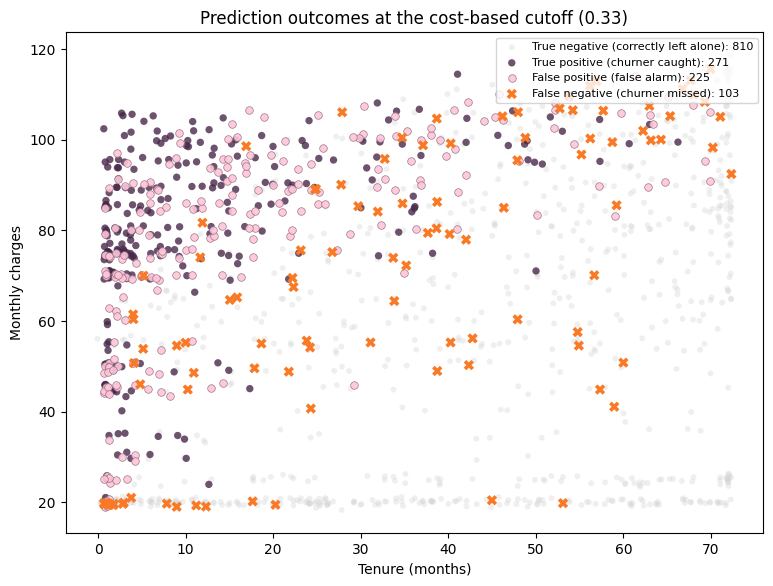

In [34]:
rng = np.random.default_rng(42)
tenure = X_test["tenure"].to_numpy() + rng.uniform(-0.35, 0.35, len(y))   # jitter for visibility only
charges = X_test["monthly_charges"].to_numpy()

groups = [  # errors are drawn last so they stay visible
    ("True negative (correctly left alone)", (y == 0) & (pred_final == 0), "lightgray", 0.35, 18, "o"),
    ("True positive (churner caught)",       (y == 1) & (pred_final == 1), PURPLE, 0.8, 28, "o"),
    ("False positive (false alarm)",         (y == 0) & (pred_final == 1), PINK, 0.9, 30, "o"),
    ("False negative (churner missed)",      (y == 1) & (pred_final == 0), ORANGE, 1.0, 55, "X"),
]

fig, ax = plt.subplots(figsize=(9, 6.5))
for label, mask, color, alpha, size, marker in groups:
    ax.scatter(tenure[mask], charges[mask], c=color, alpha=alpha, s=size, marker=marker,
               edgecolors=MAUVE if color == PINK else "none", linewidths=0.5,
               label=f"{label}: {mask.sum()}")
ax.set_xlabel("Tenure (months)"); ax.set_ylabel("Monthly charges")
ax.set_title(f"Prediction outcomes at the cost-based cutoff ({final_cutoff:.2f})")
ax.legend(loc="upper right", fontsize=8)
plt.savefig("../outputs/plots/outcome_scatter_final.png", dpi=150, bbox_inches="tight")
plt.show()

In [35]:
seg = pd.DataFrame({
    "contract": np.where(X_test["contract_Two year"].to_numpy() == 1, "Two year",
                 np.where(X_test["contract_One year"].to_numpy() == 1, "One year", "Month-to-month")),
    "tenure_band": pd.cut(X_test["tenure"].to_numpy(), [-1, 11, 35, 72],
                          labels=["0-11 months", "12-35 months", "36-72 months"]),
    "y": y,
    "flag": pred_final,
})
seg["hit"] = (seg.flag == 1) & (seg.y == 1)

def seg_table(col):
    g = seg.groupby(col, observed=True).agg(customers=("y", "size"), churners=("y", "sum"),
                                            flagged=("flag", "sum"), hits=("hit", "sum"))
    g["churn_rate"] = (g.churners / g.customers).round(2)
    g["recall"] = (g.hits / g.churners).round(2)
    g["precision"] = (g.hits / g.flagged).round(2)
    return g

display(seg_table("contract"))
display(seg_table("tenure_band"))

,customers,churners,flagged,hits,churn_rate,recall,precision
contract,,,,,,,
Month-to-month,770,326,489,269,0.42,0.83,0.55
One year,287,37,7,2,0.13,0.05,0.29
Two year,352,11,0,0,0.03,0.00,NaN


,customers,churners,flagged,hits,churn_rate,recall,precision
tenure_band,,,,,,,
0-11 months,414,202,291,179,0.49,0.89,0.62
12-35 months,364,97,140,66,0.27,0.68,0.47
36-72 months,631,75,65,26,0.12,0.35,0.40


## Final-cutoff diagnostics: results

### Confusion matrix at the cost-based cutoff (0.333, calibrated probabilities)

| | Predicted stays | Predicted churns |
|---|---|---|
| **Actually stayed** | 810 (78%) | 225 (22%) |
| **Actually churned** | 103 (28%) | 271 (72%) |

496 of 1,409 customers are flagged (35%). Recall is 0.725 and precision is 0.546.

**Against the earlier 0.5 placeholder** (raw, inflated scores, 604 flags): there are 108 fewer flags, made up of 74 fewer false alarms (299 to 225) and 34 fewer churners caught (305 to 271). Recall went from 0.82 to 0.73 and precision from 0.51 to 0.55. The 108 removed flags churned at about 31% (34 of 108), close to the 33% break-even, which is what the cost rule says such customers are worth.

### Outcome scatter (tenure and monthly charges)
The four groups match the matrix (810 true negatives, 271 true positives, 225 false alarms, 103 missed). True positives and false alarms sit in the same region, the first year of tenure with mid-to-high bills, and are mixed together there. Read by eye, the missed churners appear in three places: a band at about 20 monthly charges with short tenure (probably cheap phone-only plans), a group at long tenure with high bills (top right), and a scattering through mid-range bills. The plot shows only two of the 30 features.

### Segment tables (test set)

| Contract | Customers | Churners | Flagged | Caught | Churn rate | Recall | Precision |
|---|---|---|---|---|---|---|---|
| Month-to-month | 770 | 326 | 489 | 269 | 0.42 | 0.83 | 0.55 |
| One year | 287 | 37 | 7 | 2 | 0.13 | 0.05 | 0.29 |
| Two year | 352 | 11 | 0 | 0 | 0.03 | 0.00 | n/a |

| Tenure | Customers | Churners | Flagged | Caught | Churn rate | Recall | Precision |
|---|---|---|---|---|---|---|---|
| 0-11 months | 414 | 202 | 291 | 179 | 0.49 | 0.89 | 0.62 |
| 12-35 months | 364 | 97 | 140 | 66 | 0.27 | 0.68 | 0.47 |
| 36-72 months | 631 | 75 | 65 | 26 | 0.12 | 0.35 | 0.40 |

### Findings
1. **The model splits customers into two groups.** The 496 flagged customers churn at 54.6%, and the 913 left alone churn at 11.3% (103 of 913), against 26.5% overall.
2. **Flags are almost all month-to-month** (489 of 496). Within that group, flagging 64% of customers (489 of 770) catches 83% of its churners, against about 64% if the same share were flagged at random.
3. **Early-life churners are caught best.** In the first 12 months, recall is 0.89 and precision 0.62, and this band holds 54% of all churners (202 of 374).
4. **Where the 103 misses are.** By contract: 57 month-to-month, 35 one-year, 11 two-year. By tenure: 23 in the first year, 31 in months 12 to 35, and 49 at 36 months or more.
5. **Why the misses cluster there.** The segments with the most misses have base churn rates below the 0.33 break-even: one-year contracts 0.13, two-year 0.03, tenure of 36 months or more 0.12. A discount would lose money on average in those segments, so leaving most of those customers alone is the intended outcome of the cost rule. In the 36-72 month band, the customers left alone churn at 8.7% (49 of 566), while the 65 flagged there did better than break-even (precision 0.40).
6. **Implication.** The discount works as a campaign aimed at new month-to-month customers. Churners on longer contracts or with long tenure are rare and hard to pick out, and if they matter, an intervention other than a discount may be needed (an idea, not tested here).

### Caveats
Some cells rest on few customers (11 two-year churners, 37 one-year), so the recall figures there are noisy. The scatter reading is by eye, and these diagnostics are on the test set only.

In [36]:
flag_m2m = (X_test["contract_One year"].to_numpy() == 0) & (X_test["contract_Two year"].to_numpy() == 0)
s_m2m = net_saving(flag_m2m, y, B)
print("All month-to-month | flagged", flag_m2m.sum(), "| net saving", round(s_m2m),
      "| per 1,000", round(s_m2m / len(y) * 1000))

All month-to-month | flagged 770 | net saving 48759 | per 1,000 34606


In [37]:
# 1) Like-for-like: the model's top 770 customers vs. the 770 month-to-month customers
k_m2m = int(flag_m2m.sum())
flag_top770 = np.zeros(len(y), dtype=bool)
flag_top770[np.argsort(-p_cal)[:k_m2m]] = True
s_top770 = net_saving(flag_top770, y, B)
print("Model, same", k_m2m, "flags | net saving", round(s_top770), "| per 1,000", round(s_top770 / len(y) * 1000))

# 2) Bootstrap: model at the final cutoff minus all-month-to-month (paired resamples)
rng = np.random.default_rng(42)
gain = []
for _ in range(2000):
    idx = rng.integers(0, len(y), len(y))
    yb, Bb = y[idx], B[idx]
    gain.append(net_saving(flag_model[idx], yb, Bb) - net_saving(flag_m2m[idx], yb, Bb))
lo, hi = np.percentile(gain, [2.5, 97.5])
print(f"Model at {cutoff_rule:.2f} minus all-month-to-month: mean {np.mean(gain):,.0f} | 95% interval {lo:,.0f} to {hi:,.0f}")

# 3) Sensitivity: the model (cutoff adapted to each r) vs. all-month-to-month
rows = []
for r_ in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    cut_r = d / (d + r_ * (1 - d))
    rows.append({"r": r_,
                 "model_adapted": round(net_saving(p_cal >= cut_r, y, B, r=r_)),
                 "all_month_to_month": round(net_saving(flag_m2m, y, B, r=r_))})
display(pd.DataFrame(rows))

Model, same 770 flags | net saving 50179 | per 1,000 35613
Model at 0.33 minus all-month-to-month: mean 11,974 | 95% interval 6,101 to 18,143


,r,model_adapted,all_month_to_month
0,0.1,2553,-44186
1,0.2,10439,-20949
2,0.3,28420,2287
3,0.4,42581,25523
4,0.5,60674,48759
5,0.6,82395,71996
6,0.7,104828,95232


In [38]:
print(round(breakeven_r(flag_m2m), 3))

0.29


## Stronger baseline: offering to every month-to-month customer

### Why this check was added
The segment table showed month-to-month customers churn at 42%, above the 33% break-even, so a trivial rule (offer to every month-to-month customer) can be profitable on its own. The first naive rule (month-to-month and tenure under 12 months) was narrower and weaker, because its tenure condition removed profitable customers. Claims about the model should be made against the strongest simple rule, so it was added.

### Results (test set, r = 0.5, d = 0.2, M = 12)

| Strategy | Flags | Net saving | Per 1,000 customers |
|---|---|---|---|
| Naive rule (month-to-month and tenure under 12) | 385 | 43,079 | 30,574 |
| All month-to-month (strongest simple rule) | 770 | 48,759 | 34,606 |
| Model, same 770 flags | 770 | 50,179 | 35,613 |
| **Model at the cost-based cutoff 0.33** | **496** | **60,674** | **43,062** |

Paired bootstrap (2,000 resamples of the test customers): model at 0.33 minus all month-to-month has a mean of 11,974 and a 95% interval of 6,101 to 18,143, entirely above zero. This covers test-sample noise only, not uncertainty in r, d and M.

### Where the gain comes from
The model's lead over all month-to-month (11,915) splits into two parts:
- **Ranking at equal volume: 1,420 (12%).** With the same 770 flags, the model's top 770 earns 50,179 against 48,759 for the month-to-month group. This is small and was not tested for significance, so it may be within noise.
- **Deciding how many to contact: 10,495 (88%).** Moving from 770 to 496 flags removes 281 month-to-month customers who churn at only 20% (57 of 281), below the 33% break-even, so a discount to them loses money on average.

The model's advantage over a contract-type rule is therefore mostly the calibrated probability and the cost-based cutoff, which show who to leave out, more than a better ranking inside the high-risk group. It contacts 36% fewer customers (496 against 770) and earns about 24% more (60,674 against 48,759), roughly 8,500 more per 1,000 customers.

### Sensitivity to the offer success rate r

| r | Model (cutoff adapted to r) | All month-to-month | Model's lead |
|---|---|---|---|
| 0.1 | 2,553 | -44,186 | 46,739 |
| 0.2 | 10,439 | -20,949 | 31,388 |
| 0.3 | 28,420 | 2,287 | 26,133 |
| 0.4 | 42,581 | 25,523 | 17,058 |
| 0.5 | 60,674 | 48,759 | 11,915 |
| 0.6 | 82,395 | 71,996 | 10,399 |
| 0.7 | 104,828 | 95,232 | 9,596 |

The model wins at every r tested, and its lead is largest when offers work poorly, because the cutoff rises and it contacts only the most likely churners, while the month-to-month rule keeps handing out discounts.

**Break-even r** (the lowest offer success rate at which a policy still makes money, flagged set fixed): all month-to-month 0.29, model at 0.33 0.203, narrower naive rule 0.171. The narrower rule has the lowest value because it flags only the highest-risk group (new month-to-month customers), but it earns less at r = 0.5 (43,079), and the adapted model beats it at every r tested.

### Caveats
- "Strongest simple rule" means the strongest of the rules tried here, not an exhaustive search. A rule tuned on training data, or the Logistic Regression finalist, could close part of the gap. Neither was tested.
- r, d and M are assumptions, and totals cover the 1,409 test customers only (about 20% of the base).
- Contact costs are ignored, and every false alarm is assumed to take the discount.

In [39]:

import shap
import matplotlib.pyplot as plt

# Explain the fitted LightGBM model
explainer = shap.TreeExplainer(final_model)

# Use a manageable sample from the training data
X_shap = X_train.sample(
    n=min(1000, len(X_train)),
    random_state=42
)

# Calculate SHAP values
shap_values = explainer(X_shap)

print("SHAP values calculated successfully.")
print("Shape:", shap_values.values.shape)


SHAP values calculated successfully.
Shape: (1000, 30)


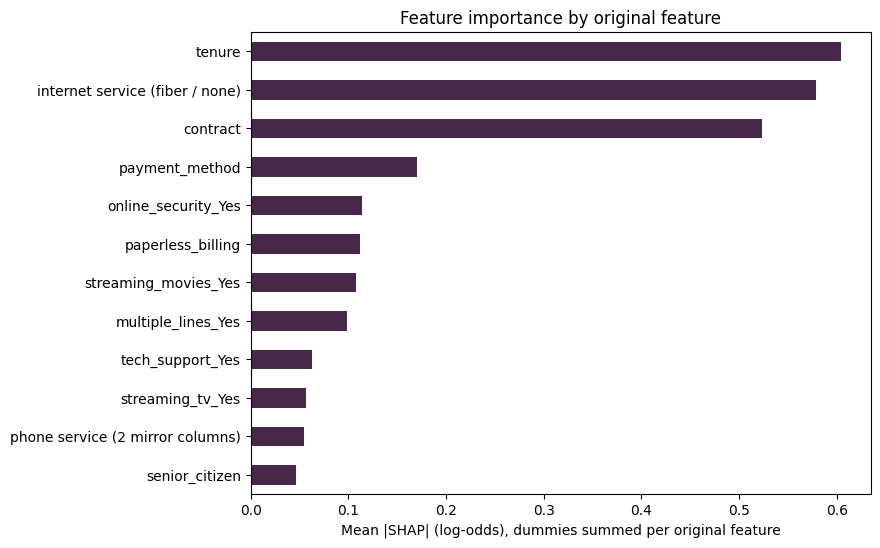

In [40]:
cols = list(X_shap.columns)
def with_prefix(p): return [c for c in cols if c.startswith(p + "_")]

no_internet = ["internet_service_No"] + [c for c in cols if c.endswith("No internet service")]
groups = {
    "internet service (fiber / none)": ["internet_service_Fiber optic"] + no_internet,
    "contract": with_prefix("contract"),
    "payment_method": with_prefix("payment_method"),
    "phone service (2 mirror columns)": ["phone_service", "multiple_lines_No phone service"],
}
used = {c for g in groups.values() for c in g}
groups.update({c: [c] for c in cols if c not in used})

sv = shap_values.values
grouped = pd.DataFrame({g: sv[:, [cols.index(c) for c in m]].sum(axis=1) for g, m in groups.items()})
grouped_imp = grouped.abs().mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
grouped_imp.head(12)[::-1].plot.barh(color="#48284a", ax=ax)
ax.set_xlabel("Mean |SHAP| (log-odds), dummies summed per original feature")
ax.set_title("Feature importance by original feature")
plt.savefig("../outputs/plots/shap_grouped_importance.png", dpi=150, bbox_inches="tight")
plt.show()

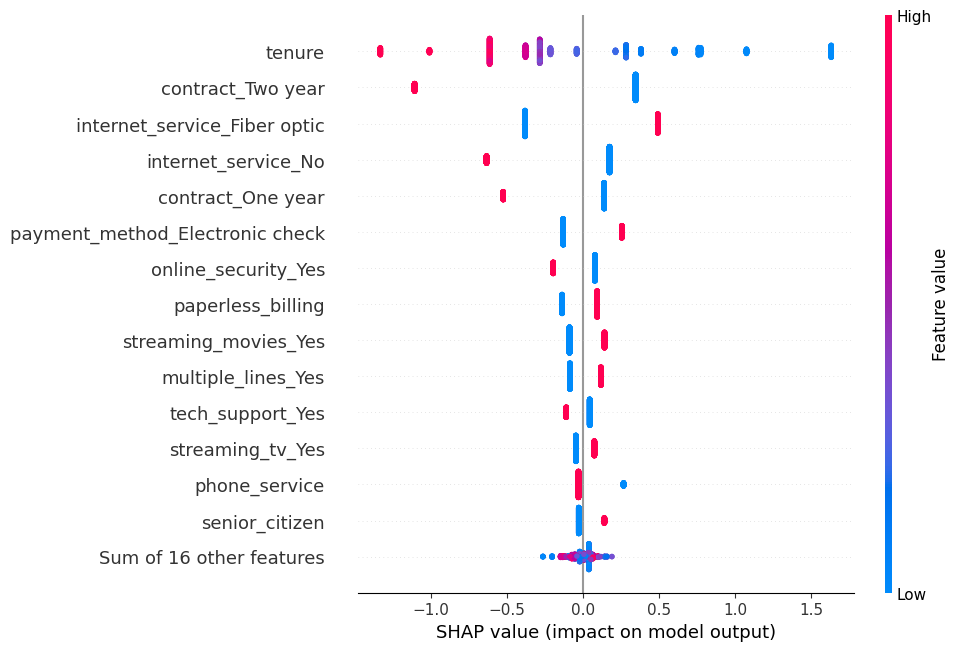

In [41]:

shap.plots.beeswarm(shap_values, max_display=15)


In [42]:
print("Number of trees:",
      final_model.booster_.num_trees())

print("Tree information:")
for i, tree in enumerate(
    final_model.booster_.dump_model()["tree_info"][:5]
):
    print(
        f"Tree {i}:",
        "leaves =", tree["num_leaves"],
        "| split feature =", tree["tree_structure"].get("split_feature")
    )



Number of trees: 348
Tree information:
Tree 0: leaves = 2 | split feature = 26
Tree 1: leaves = 2 | split feature = 26
Tree 2: leaves = 2 | split feature = 26
Tree 3: leaves = 2 | split feature = 11
Tree 4: leaves = 2 | split feature = 5


In [43]:
dump = final_model.booster_.dump_model()
print("Distinct leaf counts across all trees:", sorted({t["num_leaves"] for t in dump["tree_info"]}))

imp = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_shap.columns).sort_values(ascending=False)
display(imp.round(3).to_frame("mean_abs_shap"))
imp.round(3).to_csv("../outputs/shap_importance.csv")

Distinct leaf counts across all trees: [2]


,mean_abs_shap
tenure,0.604
contract_Two year,0.519
internet_service_Fiber optic,0.428
internet_service_No,0.276
contract_One year,0.230
payment_method_Electronic check,0.170
online_security_Yes,0.114
paperless_billing,0.112
streaming_movies_Yes,0.108
multiple_lines_Yes,0.099


Churner caught (highest risk) | calibrated churn probability 0.93


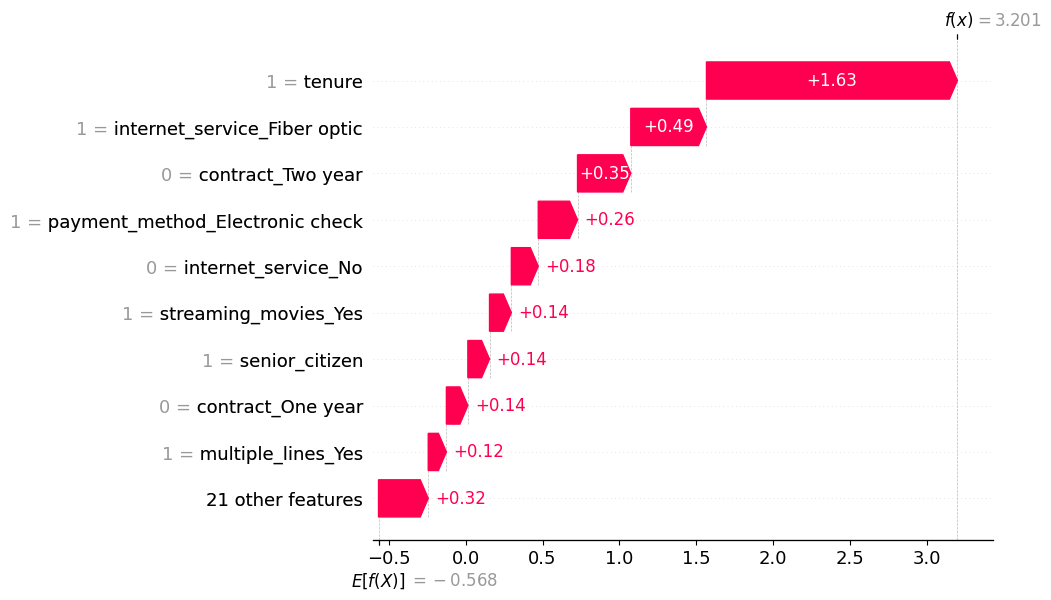

False alarm (flagged, stayed) | calibrated churn probability 0.88


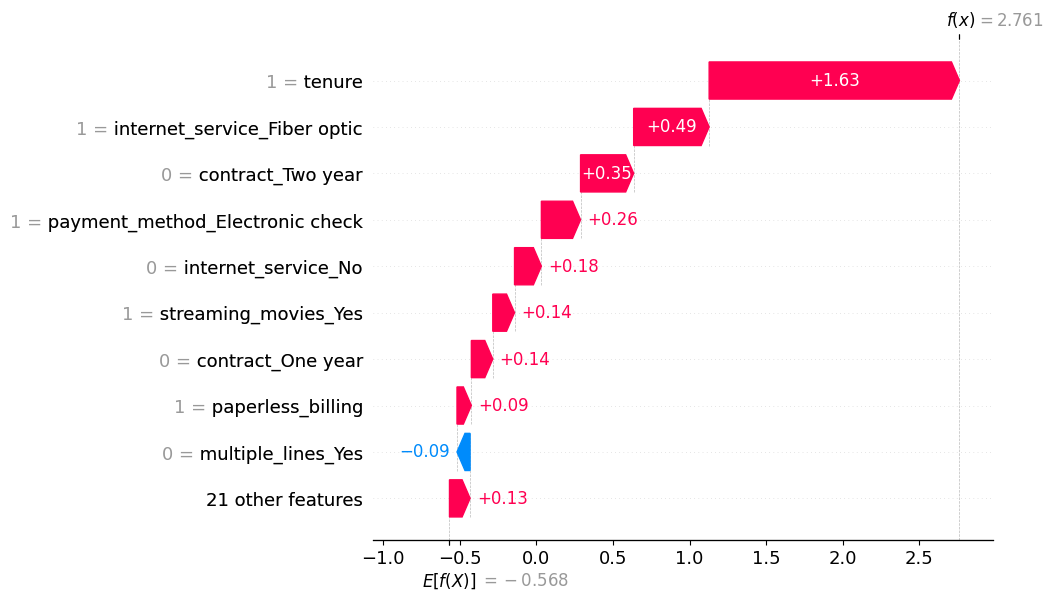

Churner missed (lowest risk) | calibrated churn probability 0.01


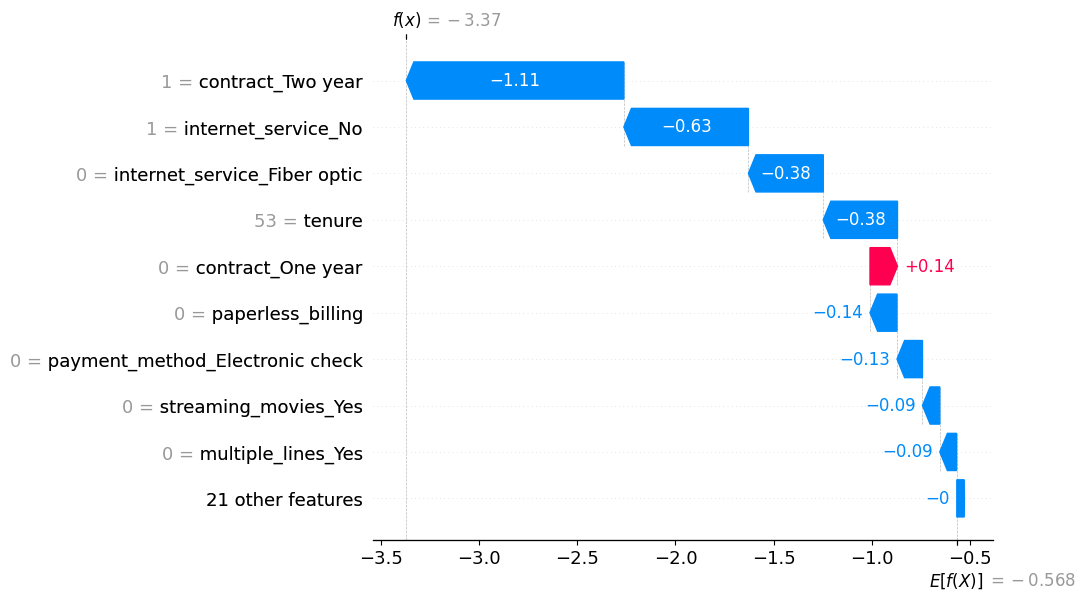

In [44]:
shap_test = explainer(X_test)
y_arr = np.asarray(y_test).astype(int)
flag = p_cal >= cutoff_rule

def pick(mask, highest=True):
    idx = np.where(mask)[0]
    return idx[np.argmax(p_cal[idx])] if highest else idx[np.argmin(p_cal[idx])]

cases = {
    "Churner caught (highest risk)": pick(flag & (y_arr == 1)),
    "False alarm (flagged, stayed)": pick(flag & (y_arr == 0)),
    "Churner missed (lowest risk)": pick(~flag & (y_arr == 1), highest=False),
}
for title, i in cases.items():
    print(f"{title} | calibrated churn probability {p_cal[i]:.2f}")
    shap.plots.waterfall(shap_test[i], max_display=10)

## SHAP analysis: what drives the tuned LightGBM

### Setup
SHAP's `TreeExplainer` explains the fitted LightGBM (the raw model, before the calibrator). Global plots use a random sample of 1,000 training rows. The individual cases use the test set. Values are in raw model log-odds: positive pushes toward churn, and they are not probabilities. The sigmoid calibrator sits on top and preserves order, but its slope was not checked, so odds multipliers are approximate on the calibrated scale.

**The model is additive.** All 348 trees have exactly 2 leaves (checked across all trees), so each feature's effect depends only on its own value and effects add in log-odds. This is why the beeswarm shows one or two stripes per binary feature, and why no feature shows a spread-out cloud (no interactions). It is also consistent with Logistic Regression staying competitive in Stage A.

### Importance, grouped by original feature
The per-column bar chart splits one variable across several columns (contract has two dummies, internet service has a fiber and a no-internet column), so it understates them. SHAP is additive, so summing a variable's columns per customer gives its true contribution.

| Rank | Feature | Mean abs SHAP |
|---|---|---|
| 1 | tenure | 0.604 |
| 2 | internet service (fiber / none) | ~0.58 |
| 3 | contract | ~0.52 |
| 4 | payment method (electronic check) | 0.170 |
| 5 | online security | 0.114 |
| 6 | paperless billing | 0.112 |
| 7 | streaming movies | 0.108 |
| 8 | multiple lines | 0.099 |
| 9-12 | tech support, streaming TV, phone service, senior citizen | 0.063 to 0.046 |
| 13 | total charges | 0.039 |
| 14 | monthly charges | 0.035 |
| 15-16 | dependents, online backup | 0.025, 0.015 |
| 17-19 | gender, partner, device protection | 0 |

Tenure, internet service and contract make up roughly two-thirds (about 64%) of the summed importance. In the per-column chart, internet service looked third behind contract. Grouped, it is second, because its effect is split between the fiber (0.428) and no-internet (0.276) columns.

### Direction of the effects (beeswarm and waterfalls)
- **Short tenure raises risk.** The effect runs from about +1.6 (brand-new customers) to about -1.4 (long tenure), roughly a 20-fold gap in odds, other features equal.
- **Contract:** month-to-month adds about +0.49 in total, two-year about -0.97.
- **Internet:** fiber optic raises risk (+0.49), no internet lowers it (-0.63).
- **Electronic check raises risk** (+0.26 if used, about -0.13 if not).
- **Online security and tech support lower risk.** Streaming, multiple lines, paperless billing and senior citizen raise it slightly.
- **Streaming movies pushes toward churn**, although its raw churn rate in EDA was slightly lower. With tenure, contract and internet type held fixed it likely stands in for bundled or premium plans. This is a guess, not tested.

### Features the model never uses
12 of 30 columns have zero importance:
- Six "No internet service" columns exactly duplicate `internet_service_No`, so the model uses one copy. `multiple_lines_No phone service` is a similar mirror of `phone_service`.
- The `gender` column had no signal in EDA. `partner` and `device_protection_Yes` showed gaps in EDA, but the model finds nothing extra once other features are known (probably because they overlap with tenure, contract and dependents).
- Of the payment methods, only the electronic-check column is used.

### Decision on total_charges
It ranks 13th of 19 original features (0.039, about 6% of tenure's importance), and so does monthly_charges (0.035). The model cannot multiply features (all trees are single splits), so total_charges adds little beyond tenure and the plan columns. It is **kept**: it is used a little, and dropping it would mean refitting, recalibrating and re-deriving the cutoff and savings. If the app needs fewer inputs, the 12 unused columns and total_charges are the candidates to remove, followed by a refit.

### Individual cases (test set, raw log-odds, baseline -0.568)

| Case | Calibrated p | Main drivers |
|---|---|---|
| Churner caught (highest-risk churner) | 0.93 | tenure 1 month (+1.63), fiber (+0.49), no two-year contract (+0.35), electronic check (+0.26) |
| False alarm (highest-p customer who stayed) | 0.88 | nearly the same profile: tenure 1 month (+1.63), fiber (+0.49), no two-year contract (+0.35), electronic check (+0.26) |
| Churner missed (lowest-p churner) | 0.01 | two-year contract (-1.11), no internet (-0.63), tenure 53 months (-0.38), no fiber (-0.38) |

- **The false alarm is not a modelling error.** Its profile is almost identical to the caught churner's (they differ by a few small items worth about 0.1 each). A calibrated 0.88 means about 12 in 100 such customers stay, and this was one of them.
- **The missed churner had no warning signs in the data.** Everything about the customer points to staying.
- **Both extremes were picked on purpose** (highest p among false alarms, lowest p among misses), so they show the extremes, not typical cases.

### Takeaways and caveats
- The highest-risk profile in the model is a new customer on a month-to-month fiber plan paying by electronic check, which matches EDA and the segment tables.
- SHAP shows what the model uses, not what causes churn. Fiber, for example, may stand in for price or service quality.
- The two grouped values marked ~ are read off the chart. Global importance comes from a 1,000-row training sample.

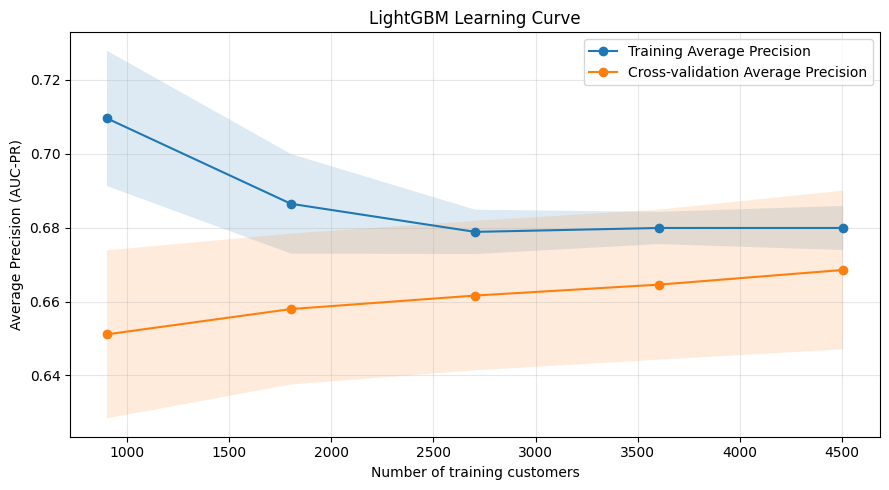

,training_customers,training_AP_mean,training_AP_std,cv_AP_mean,cv_AP_std
0,901,0.7096,0.0183,0.6511,0.0227
1,1802,0.6865,0.0135,0.6580,0.0204
2,2704,0.6789,0.0060,0.6616,0.0202
3,3605,0.6799,0.0044,0.6646,0.0203
4,4507,0.6799,0.0060,0.6686,0.0215


In [45]:

from sklearn.model_selection import learning_curve, StratifiedKFold

# Use the same 5-fold CV 
cv_learning = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the tuned LightGBM using training data only
train_sizes, train_scores, cv_scores = learning_curve(
    estimator=final_model,
    X=X_train,
    y=y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv_learning,
    scoring="average_precision",
    n_jobs=1,
    shuffle=True,
    random_state=42
)

# Mean and standard deviation across the 5 folds
train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

cv_mean = cv_scores.mean(axis=1)
cv_std = cv_scores.std(axis=1)

# Plot the learning curve
plt.figure(figsize=(9, 5))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training Average Precision"
)

plt.plot(
    train_sizes,
    cv_mean,
    marker="o",
    label="Cross-validation Average Precision"
)

plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15
)

plt.fill_between(
    train_sizes,
    cv_mean - cv_std,
    cv_mean + cv_std,
    alpha=0.15
)

plt.xlabel("Number of training customers")
plt.ylabel("Average Precision (AUC-PR)")
plt.title("LightGBM Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display exact numerical results
learning_results = pd.DataFrame({
    "training_customers": train_sizes,
    "training_AP_mean": train_mean,
    "training_AP_std": train_std,
    "cv_AP_mean": cv_mean,
    "cv_AP_std": cv_std
})

display(learning_results.round(4))


## Learning curve

### What was computed
The tuned LightGBM (fixed hyperparameters) was trained on growing subsets of the training data (20% to 100% of each fold's training portion) with the same 5-fold stratified split used for tuning, and scored with AUC-PR on both the data it was trained on and the held-out fold. With 5 folds, each fold trains on 80% of the 5,634 training customers, so the largest point is 4,507 customers, one step short of the 5,634 used for the final model.

### Results

| Training customers | Training AUC-PR | CV AUC-PR | Gap |
|---|---|---|---|
| 901 | 0.7096 | 0.6511 | 0.0585 |
| 1,802 | 0.6865 | 0.6580 | 0.0285 |
| 2,704 | 0.6789 | 0.6616 | 0.0173 |
| 3,605 | 0.6799 | 0.6646 | 0.0153 |
| 4,507 | 0.6799 | 0.6686 | 0.0113 |

The fold-to-fold standard deviation of the CV score stays about 0.02 at every size.

### Interpretation
- **No overfitting.** The gap narrows steadily to 0.0113, about half the fold-to-fold standard deviation. The training score is only 0.68, so the model is not memorizing, and it falls from 0.71 as data grows, the normal pattern as a small sample becomes harder to fit exactly.
- **The model is limited by capacity, not by data.** The training curve is flat from 2,704 customers on (0.6789 to 0.6799), and CV is still creeping up but slowly (+0.004 at the last step, +0.007 over the last 1,800 customers, against a standard deviation of 0.02). If the curves met, CV would gain only about the remaining 0.011. This fits the SHAP finding that every tree has 2 leaves, so the model is additive with no interactions. More customers would add little. More tree depth was already tried and scored lower, so improvement, if any, would more likely come from better input features (a hypothesis, not tested here).
- **Consistency across estimates:** training 0.680, CV 0.669 and test 0.655 step down gradually with no cliff, which is further evidence of no overfitting (the training sizes differ slightly, so this is approximate).

### Caveat
The CV scores use the same folds the hyperparameters were tuned on, and the last point (0.6686) equals the best Optuna score for this configuration, so the CV curve is slightly optimistic. The fresh-seed score (0.6705) and the test score (0.655) are the more independent estimates.

## Saving the deployment artifacts

Saved to `models/` (all fit on training data only, so they are the exact objects behind every reported number):
- `churn_model_calibrated.joblib`: LightGBM plus the sigmoid calibrator, columns in and calibrated probability out.
- `lgbm_raw.joblib`: the plain LightGBM, kept for SHAP explanations in the app (SHAP explains the model before the calibrator).
- `model_config.json`: feature order, hyperparameters, default business assumptions (r, d, M) with the cutoff formula, test metrics and library versions.
- `reference_stats.json`: training-set distributions and the test-set score distribution, the baseline for the monitoring notes.
- `encoder.joblib`: saved in the feature engineering notebook.

Column order is stored because LightGBM does not check column names at prediction time, so a reordered row would be scored wrongly without any error.

In [46]:
import os, sys, json, platform, importlib.metadata as md
from datetime import datetime
import numpy as np
import pandas as pd
import joblib, sklearn, lightgbm, shap
from sklearn.metrics import average_precision_score, recall_score, precision_score

os.makedirs("../models", exist_ok=True)

y_arr = np.asarray(y_test).astype(int)
B_test = X_test["monthly_charges"].to_numpy()
p_test = cal_sigmoid.predict_proba(X_test)[:, 1]
flag = p_test >= cutoff_rule
numeric_cols = ["tenure", "monthly_charges", "total_charges"]

# Integrity: the raw model we saved (for SHAP) must match the model inside the calibrator
inner = cal_sigmoid.calibrated_classifiers_[0]
inner_est = getattr(inner, "estimator", None) or getattr(inner, "base_estimator", None)
same = np.allclose(inner_est.predict_proba(X_test)[:, 1], final_model.predict_proba(X_test)[:, 1])
print("final_model matches the model inside the calibrator:", same)

joblib.dump(cal_sigmoid, "../models/churn_model_calibrated.joblib")
joblib.dump(final_model, "../models/lgbm_raw.joblib")

saving = net_saving(flag, y_arr, B_test, r=r, d=d, M=M)
config = {
    "created": datetime.now().isoformat(timespec="seconds"),
    "feature_order": list(X_train.columns),
    "model": {
        "description": "LightGBM (class-weighted) + sigmoid calibration (CalibratedClassifierCV, ensemble=False, 5-fold), fit on training data only",
        "hyperparameters": {**{k: (int(v) if float(v).is_integer() else float(v)) for k, v in final_params.items()},
                            "scale_pos_weight": float(scale_pos_weight)},
    },
    "business_defaults": {
        "offer_success_rate_r": float(r), "discount_d": float(d), "months_retained_M": int(M),
        "cutoff_formula": "d / (d + r * (1 - d))", "cutoff": float(cutoff_rule),
    },
    "test_metrics_at_cutoff": {
        "n_test": int(len(y_arr)), "n_churners": int(y_arr.sum()),
        "auc_pr": float(average_precision_score(y_arr, p_test)),
        "recall": float(recall_score(y_arr, flag)), "precision": float(precision_score(y_arr, flag)),
        "flagged": int(flag.sum()),
        "net_saving_12m_currency_units": float(saving),
        "net_saving_per_1000_customers": float(saving / len(y_arr) * 1000),
    },
    "library_versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                         "lightgbm": lightgbm.__version__, "shap": shap.__version__,
                         "pandas": pd.__version__, "numpy": np.__version__},
}
json.dump(config, open("../models/model_config.json", "w"), indent=2)

q = [0.05, 0.25, 0.5, 0.75, 0.95]
reference = {
    "source": "feature statistics from the training set; score statistics from the test set (out-of-sample)",
    "n_train": int(len(X_train)), "train_churn_rate": float(np.mean(y_train)),
    "numeric_features": {c: {"mean": float(X_train[c].mean()), "std": float(X_train[c].std()),
                             "quantiles": {str(p): float(X_train[c].quantile(p)) for p in q}} for c in numeric_cols},
    "feature_means": {c: float(X_train[c].mean()) for c in X_train.columns},
    "test_calibrated_score": {"mean": float(p_test.mean()),
                              "quantiles": {str(p): float(np.quantile(p_test, p)) for p in q}},
    "test_flag_rate_at_cutoff": float(flag.mean()),
}
json.dump(reference, open("../models/reference_stats.json", "w"), indent=2)

for f in sorted(os.listdir("../models")):
    print(f"{f:32s} {os.path.getsize(os.path.join('../models', f)) / 1024:8.1f} KB")

print("\nPin these in requirements.txt:")
import platform, importlib.metadata as md
print("python", platform.python_version())
for p in ["numpy", "pandas", "pydantic", "scikit-learn", "lightgbm", "joblib", "shap",
          "SQLAlchemy", "psycopg2-binary", "python-dotenv", "streamlit", "plotly",
          "fastapi", "uvicorn", "httpx", "requests", "pytest", "ruff", "python-multipart"]:
    try:
        print(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        print(f"# {p} not installed")

final_model matches the model inside the calibrator: True
churn_model_calibrated.joblib       139.9 KB
encoder.joblib                        4.9 KB
lgbm_raw.joblib                     134.6 KB
model_config.json                     2.0 KB
reference_stats.json                  2.8 KB

Pin these in requirements.txt:
python 3.11.3
numpy==2.4.6
pandas==2.3.0
# pydantic not installed
scikit-learn==1.7.0
lightgbm==4.7.0
joblib==1.5.1
shap==0.51.0
SQLAlchemy==2.0.39
psycopg2-binary==2.9.10
python-dotenv==1.2.3
streamlit==1.46.1
# plotly not installed
# fastapi not installed
# uvicorn not installed
httpx==0.28.1
requests==2.32.3
# pytest not installed
# ruff not installed
# python-multipart not installed


In [47]:
loaded_model = joblib.load("../models/churn_model_calibrated.joblib")
loaded_raw = joblib.load("../models/lgbm_raw.joblib")
cfg = json.load(open("../models/model_config.json"))

X_check = X_test[cfg["feature_order"]]
p_loaded = loaded_model.predict_proba(X_check)[:, 1]
bd = cfg["business_defaults"]
cut = bd["offer_success_rate_r"], bd["discount_d"]
cutoff_loaded = cut[1] / (cut[1] + cut[0] * (1 - cut[1]))
flag_loaded = p_loaded >= cutoff_loaded

print("Max difference vs. notebook probabilities:", np.abs(p_loaded - p_cal).max())
print("Cutoff from config matches:", np.isclose(cutoff_loaded, cutoff_rule))
print("Flagged:", int(flag_loaded.sum()), "| identical flags:", np.array_equal(flag_loaded, p_cal >= cutoff_rule))
print("Recall:", round(recall_score(y_arr, flag_loaded), 3), "| precision:", round(precision_score(y_arr, flag_loaded), 3))
print("Raw model matches final_model:", np.allclose(loaded_raw.predict_proba(X_check)[:, 1],
                                                    final_model.predict_proba(X_check)[:, 1]))

Max difference vs. notebook probabilities: 0.0
Cutoff from config matches: True
Flagged: 496 | identical flags: True
Recall: 0.725 | precision: 0.546
Raw model matches final_model: True


In [48]:
print(json.load(open("../models/model_config.json"))["test_metrics_at_cutoff"])

{'n_test': 1409, 'n_churners': 374, 'auc_pr': 0.6550365584880613, 'recall': 0.7245989304812834, 'precision': 0.5463709677419355, 'flagged': 496, 'net_saving_12m_currency_units': 60674.15999999998, 'net_saving_per_1000_customers': 43061.85947480481}


## Saving everything for the dashboard 

In [50]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score, brier_score_loss,
                             precision_recall_curve, recall_score, precision_score)
from sklearn.calibration import calibration_curve

os.makedirs("../reports", exist_ok=True)

CUTOFF = d / (d + r * (1 - d))           
y_arr = np.asarray(y_test).astype(int)
p_raw = final_model.predict_proba(X_test)[:, 1]
p_cal = cal_sigmoid.predict_proba(X_test)[:, 1]
B = X_test["monthly_charges"].to_numpy()
flag = p_cal >= CUTOFF

# 1) Per-customer test predictions (powers backtest toggle, segments, fairness, ROI page)
contract = np.where(X_test["contract_Two year"] == 1, "Two year",
            np.where(X_test["contract_One year"] == 1, "One year", "Month-to-month"))
tenure_band = pd.cut(X_test["tenure"].to_numpy(), [-1, 11, 35, 72],
                     labels=["0-11", "12-35", "36-72"]).astype(str)
# Link each test row to its customer using the frozen split file (made in notebook 03).
# "position" = row number inside X_test.pkl, which is in the same order as this X_test.
sa = pd.read_csv("../data/split_assignment.csv")
test_ids = sa[sa.split == "test"].sort_values("position")["customer_id"].to_numpy()
assert len(test_ids) == len(X_test) == 1409

tp = pd.DataFrame({
    "customer_id": test_ids,
    "p_raw": p_raw, "p_cal": p_cal, "actual_churn": y_arr,
    "monthly_charges": B, "tenure": X_test["tenure"].to_numpy(),
    "contract": contract, "tenure_band": tenure_band,
    "flag": flag.astype(int),
    "expected_gain": M * B * (p_cal * r * (1 - d) - (1 - p_cal) * d),
})
demo_cols = [c for c in X_test.columns if c.startswith(("gender", "senior"))]
for c in demo_cols:
    tp[c] = X_test[c].to_numpy()
tp.to_csv("../reports/test_predictions.csv", index=False)

# 2) CV comparison table (means and stds) + the ROC-AUC rerun
cv_rows = []
for name, m in results_5fold.items():
    row = {"pipeline": name}
    for metric, (mean, std) in m.items():
        row[metric], row[metric + "_std"] = mean, std
    cv_rows.append(row)
cv_df = pd.DataFrame(cv_rows).set_index("pipeline")
for name, pipe in pipelines.items():      # slow for the SMOTENC pipelines
    s = cross_val_score(pipe, X_train, y_train, cv=cv_5, scoring="roc_auc", n_jobs=-1)
    cv_df.loc[name, "roc_auc"], cv_df.loc[name, "roc_auc_std"] = s.mean(), s.std()
cv_df.to_csv("../reports/cv_results.csv")

# 3) Curve data
pr_p, pr_r, _ = precision_recall_curve(y_arr, p_cal)
pd.DataFrame({"precision": pr_p, "recall": pr_r}).to_csv("../reports/pr_curve.csv", index=False)
fpr, tpr, _ = roc_curve(y_arr, p_cal)
pd.DataFrame({"fpr": fpr, "tpr": tpr}).to_csv("../reports/roc_curve.csv", index=False)

order = np.argsort(-p_cal)
gains = pd.DataFrame({"frac_customers": np.arange(1, len(y_arr) + 1) / len(y_arr),
                      "frac_churners": np.cumsum(y_arr[order]) / y_arr.sum()})
gains.to_csv("../reports/gains_curve.csv", index=False)

cal_rows = []
for label, p in [("uncalibrated", p_raw), ("sigmoid", p_cal)]:
    frac_pos, mean_pred = calibration_curve(y_arr, p, n_bins=10, strategy="quantile")
    cal_rows.append(pd.DataFrame({"model": label, "mean_pred": mean_pred, "frac_pos": frac_pos}))
pd.concat(cal_rows).to_csv("../reports/calibration_curve.csv", index=False)

sweep.to_csv("../reports/cutoff_sweep.csv", index=False)

# 4) Segment and fairness tables (recall by segment, flag rate by group)
def group_table(df, col):
    g = df.groupby(col).agg(n=("actual_churn", "size"), churners=("actual_churn", "sum"),
                            flagged=("flag", "sum"))
    g["caught"] = df[(df.flag == 1) & (df.actual_churn == 1)].groupby(col).size()
    g = g.fillna(0)
    g["churn_rate"] = g.churners / g.n
    g["flag_rate"] = g.flagged / g.n
    g["recall"] = g.caught / g.churners.replace(0, np.nan)
    g["precision"] = g.caught / g.flagged.replace(0, np.nan)
    g.insert(0, "group_by", col)
    return g.reset_index().rename(columns={col: "group"})

seg = pd.concat([group_table(tp, c) for c in ["contract", "tenure_band"] + demo_cols])
seg.to_csv("../reports/segment_metrics.csv", index=False)

# 5) Headline metrics (Brier before/after, test metrics at the cutoff)
hit, fa = flag & (y_arr == 1), flag & (y_arr == 0)
metrics = {
    "cutoff": float(CUTOFF), "n_test": int(len(y_arr)), "n_churners": int(y_arr.sum()),
    "brier_uncalibrated": float(brier_score_loss(y_arr, p_raw)),
    "brier_sigmoid": float(brier_score_loss(y_arr, p_cal)),
    "auc_pr": float(average_precision_score(y_arr, p_cal)),
    "roc_auc": float(roc_auc_score(y_arr, p_cal)),
    "flagged": int(flag.sum()),
    "recall": float(recall_score(y_arr, flag)), "precision": float(precision_score(y_arr, flag)),
    "actual_saving_12m": float(net_saving(flag, y_arr, B, r=r, d=d, M=M)),
    "expected_saving_12m": float(tp.loc[tp.flag == 1, "expected_gain"].sum()),
    "assumptions": {"r": r, "d": d, "M": M},
    "selection_note": "Cutoff derived from d/(d+r(1-d)); no test outcomes used to choose it.",
}
json.dump(metrics, open("../reports/metrics.json", "w"), indent=2)
print("Wrote:", sorted(os.listdir("../reports")))

Wrote: ['.gitkeep', 'calibration_curve.csv', 'cutoff_sweep.csv', 'cv_results.csv', 'gains_curve.csv', 'metrics.json', 'pr_curve.csv', 'roc_curve.csv', 'segment_metrics.csv', 'test_predictions.csv']


In [51]:
import json, pandas as pd
m = json.load(open("../reports/metrics.json"))
for k in ["cutoff", "flagged", "recall", "precision", "brier_uncalibrated", "brier_sigmoid",
          "auc_pr", "roc_auc", "actual_saving_12m", "expected_saving_12m"]:
    print(f"{k:22s}", m[k])
tp = pd.read_csv("../reports/test_predictions.csv")
print(tp.shape, tp.customer_id.is_unique, tp.p_cal.between(0, 1).all(), tp.flag.sum())
print(pd.read_csv("../reports/cv_results.csv", index_col=0)[["auc_pr", "roc_auc"]].round(3))

cutoff                 0.3333333333333333
flagged                496
recall                 0.7245989304812834
precision              0.5463709677419355
brier_uncalibrated     0.16594497931754007
brier_sigmoid          0.1369225855599975
auc_pr                 0.6550365584880613
roc_auc                0.8415820610194011
actual_saving_12m      60674.15999999998
expected_saving_12m    67009.40083554618
(1409, 12) True True 496
                                auc_pr  roc_auc
pipeline                                       
LogisticRegression_SMOTENC       0.636    0.836
RandomForest_SMOTENC             0.597    0.824
XGBoost_SMOTENC                  0.606    0.820
LightGBM_SMOTENC                 0.629    0.832
LogisticRegression_ClassWeight   0.657    0.846
RandomForest_ClassWeight         0.615    0.827
XGBoost_ClassWeight              0.615    0.821
LightGBM_ClassWeight             0.640    0.835


In [52]:
# Builds reports/scores.csv: one calibrated churn probability for each of the 7,043 customers.
#   - training customers: OUT-OF-FOLD scores (each scored by a model that never saw them)
#   - test customers:     the final model's test predictions

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import average_precision_score, brier_score_loss

MODEL_VERSION = "churn-lgbm-sigmoid-v1"
CUTOFF = d / (d + r * (1 - d))                      # 0.3333..., unrounded

# 1) Out-of-fold calibrated probabilities for the 5,634 training customers.
#    clone() gives an unfitted copy of the calibrated model, so each fold refits
#    base model + calibrator on that fold's training part only.
oof = cross_val_predict(clone(cal_sigmoid), X_train, y_train, cv=cv_5,
                        method="predict_proba", n_jobs=-1)[:, 1]

# 2) Attach customer IDs from the frozen split file (position = row number in X_train.pkl)
sa = pd.read_csv("../data/split_assignment.csv")
train_ids = sa[sa.split == "train"].sort_values("position")["customer_id"].to_numpy()
assert len(train_ids) == len(X_train) == 5634

train_part = pd.DataFrame({
    "customer_id": train_ids, "split": "train", "score_kind": "oof",
    "p_cal": oof,
    "actual_churn": np.asarray(y_train).astype(int),
    "monthly_charges": X_train["monthly_charges"].to_numpy(),
})

# 3) Test customers: reuse the predictions already exported (same model, same order)
tp = pd.read_csv("../reports/test_predictions.csv")
test_part = tp[["customer_id", "p_cal", "actual_churn", "monthly_charges"]].assign(
    split="test", score_kind="test")

# 4) Combine, add the flag at the cost cutoff and the model version
cols = ["customer_id", "split", "score_kind", "p_cal", "actual_churn", "monthly_charges"]
scores = pd.concat([train_part[cols], test_part[cols]], ignore_index=True)
scores["flag"] = (scores.p_cal >= CUTOFF).astype(int)
scores["model_version"] = MODEL_VERSION
assert len(scores) == 7043 and scores.customer_id.is_unique

scores.to_csv("../reports/scores.csv", index=False)

# 5) Sanity check: out-of-fold scores should look similar to test scores, not much better
for kind, g in scores.groupby("score_kind"):
    print(f"{kind:5s} n={len(g):5d}  AUC-PR={average_precision_score(g.actual_churn, g.p_cal):.3f}  "
          f"Brier={brier_score_loss(g.actual_churn, g.p_cal):.3f}  "
          f"mean p={g.p_cal.mean():.3f}  actual churn={g.actual_churn.mean():.3f}  flagged={g.flag.sum()}")

oof   n= 5634  AUC-PR=0.666  Brier=0.133  mean p=0.265  actual churn=0.265  flagged=1933
test  n= 1409  AUC-PR=0.655  Brier=0.137  mean p=0.269  actual churn=0.265  flagged=496
